# eSIM pricing

**Notebook structure:**
1. **Analysis of the input data:** sales, cost, competitors. Every finding leads to a pricing rule.
2. **Scenario calculation** based on these rules.
3. **Scenario comparison**, charts and conclusions.

**Base requirements** that always apply:
- sales-weighted margin not below target: `TARGET_MARGIN` (1–10 GB / the rest);
- an expiring pack is cheaper than the non-expiring one, a bigger pack is not cheaper than a smaller one;
- prices in the X.Y9 € format.

All numbers in the text are computed from the variables in "Settings". Change a parameter, re-run the notebook, and the text changes with it.

## Settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Markdown, display
from openpyxl import load_workbook
from copy import copy

BASE_DIR = Path(r"C:\Users\BobR\Desktop\BE PRO")
if not BASE_DIR.exists():
    BASE_DIR = Path.cwd()
INPUT_FILE = BASE_DIR / "Pricing_analyst_task_PY.xlsx"
OUTPUT_FILE = BASE_DIR / "Pricing_analyst_task_PY_3cases.xlsx"

# base requirements
TARGET_MARGIN = {"1-10GB": 0.30, "20+GB": 0.20}      # QTY-weighted; "20+GB" group also includes Unlimited
PRICE_STEP = 0.10                                     # prices like X,Y9: 0.69, 4.49, 12.99

# rules that follow from the analysis (section 1)
OUTLIER_X = 3.0                  # competitor price 3x away from the others = data error
NOEXP_PREMIUM = {1: 0.25, 3: 0.25, 5: 0.25, 10: 0.30, 20: 0.30, 50: 0.40, 100: 0.40, 200: 0.40}
NOEXP_MAX_EUR = 20.0             # non-expiring at most +20 EUR above expiring (unless margin parity needs more)
PAIR_VALIDITY = 30               # validity (days) of the expiring pack used to price non-expiring packs
CAP_VS_TARGET = 2.0              # never above 2 x target-margin price
CASES = {
    1: {"name": "Conservative", "min_margin": 0.15, "target": "second"},
    2: {"name": "Medium",         "min_margin": 0.05, "target": "best"},
    3: {"name": "Aggressive",     "min_margin": -0.05, "target": "best"},
}
IN_MARKET_WEIGHT = 1.0           # value of a sale "in market" relative to a sale at the scenario target

# choice of the recommended scenario (section 3)
MAX_AVG_PRICE_INCREASE = 0.05    # average price for customers may grow at most +5%
MAX_SALES_BELOW_COST = 0.0       # share of sales below cost we accept

VIEW_CASE = 2                    # scenario for detailed charts
EXPORT_CASE = None               # None = recommended scenario goes to "Recommended price, euro"

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_colwidth", None)      # show long text in tables in full
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
COLORS = {0: "#9E9E9E", 1: "#2E86AB", 2: "#F18F01", 3: "#C73E1D"}
SEG_COLORS = ["#1F4E78", "#3D7CB8", "#9CC3E6", "#B85C10", "#E07A1F", "#F6C28B"]

GROUP_LABEL = {"1-3GB": "1–3 GB", "5-10GB": "5–10 GB", "1-10GB": "1–10 GB", "20+GB": "20+ GB (incl. Unlimited)"}

CHART_DIR = BASE_DIR / "charts"          # every chart is also saved here as PNG (for slides)
SAVE_CHARTS = True
plt.rcParams.update({"axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left"})

def show(name, rect=None):
    plt.tight_layout(rect=rect) if rect else plt.tight_layout()
    if SAVE_CHARTS:
        CHART_DIR.mkdir(exist_ok=True)
        plt.savefig(CHART_DIR / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

def ink(color):
    # readable text colour on top of a bar colour
    h = color.lstrip("#"); r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    return "white" if 0.299 * r + 0.587 * g + 0.114 * b < 150 else "#1B2433"

def clean_axis(ax, axis="y"):
    # hide the value axis when bars carry their own labels
    if axis == "y":
        ax.set_yticks([]); ax.spines["left"].set_visible(False)
    else:
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    ax.grid(False)

def stacked_h(ax, data, colors, total_fmt="{:,.0f}", min_share=0.05):
    # rows = bars, columns = parts (absolute values): total at the end of the bar, % of the bar inside each part
    totals = data.sum(axis=1).to_numpy(dtype=float); left = np.zeros(len(data)); y = np.arange(len(data))
    for col, color in zip(data.columns, colors):
        v = data[col].to_numpy(dtype=float); share = v / np.where(totals == 0, 1, totals)
        ax.barh(y, v, left=left, color=color, label=col)
        for yi, (l, vi, si) in enumerate(zip(left, v, share)):
            if si >= min_share and vi >= totals.max() * 0.04:
                ax.text(l + vi / 2, yi, f"{si:.0%}", ha="center", va="center", fontsize=8, color=ink(color))
        left += v
    for yi, tot in enumerate(totals):
        ax.text(tot + totals.max() * 0.01, yi, total_fmt.format(tot), va="center", fontsize=9, fontweight="bold")
    ax.set_yticks(y, data.index); ax.invert_yaxis(); ax.set_xlim(0, totals.max() * 1.15); clean_axis(ax, "x")

def say(text):
    display(Markdown(text))

def floor_desc(c):
    return f"min SKU margin {pct(c['min_margin'])}"

def pct(x, d=0):
    return f"{x:.{d}%}".replace("-", "−")

# 1. Analysis of the input data

## 1.1 Data

In [2]:
raw = pd.read_excel(INPUT_FILE, sheet_name="ALL_PRICES_REDUCED")
df = pd.DataFrame({
    "sku": raw["SKU"], "region": raw["REGION NAME"], "market": raw["Market"], "subregion": raw["Subregion"],
    "vol": raw["VOLUME"], "validity": raw["VALIDITY DAYS"], "bucket": raw["GB_bucket"],
    "cost": raw["Base cost, eur"], "qty": raw["QTY"].fillna(0),
})
df["bucket"] = np.select([df["bucket"].eq("Unlimited"), df["vol"] <= 3, df["vol"] <= 10], ["Unlimited", "1-3GB", "5-10GB"], "20+GB")
df["plan"] = np.select([df["validity"] == -1, df["bucket"] == "Unlimited"], ["non-expiring", "unlimited"], "expiring")
df["segment"] = df["plan"] + " | " + df["bucket"]
df["grp"] = np.where(df["bucket"].isin(["1-3GB", "5-10GB"]), "1-10GB", "20+GB")       # margin group: Unlimited goes with 20+GB
df["target_margin"] = df["grp"].map(TARGET_MARGIN)
df["target_price"] = df["cost"] / (1 - df["target_margin"])
BUCKETS = ["1-3GB", "5-10GB", "20+GB"]              # size buckets for reporting (margin groups stay 1-10GB / 20+GB)
SEGMENTS = [f"{p} | {b}" for p in ("expiring", "non-expiring") for b in BUCKETS]
TOTAL_QTY = df["qty"].sum()
df.head()

,sku,region,market,subregion,vol,validity,bucket,cost,qty,plan,segment,grp,target_margin,target_price
0,TR-5-GB-30,Turkey,Middle East & North Africa,Middle East,5.00,30,5-10GB,2.17,1363,expiring,expiring | 5-10GB,1-10GB,0.30,3.10
1,TR-20-GB-30,Turkey,Middle East & North Africa,Middle East,20.00,30,20+GB,7.34,1211,expiring,expiring | 20+GB,20+GB,0.20,9.18
2,TR-1-GB-30,Turkey,Middle East & North Africa,Middle East,1.00,30,1-3GB,0.51,1080,expiring,expiring | 1-3GB,1-10GB,0.30,0.73
3,TR-10-GB-30,Turkey,Middle East & North Africa,Middle East,10.00,30,5-10GB,3.99,970,expiring,expiring | 5-10GB,1-10GB,0.30,5.70
4,TR-3-GB-30,Turkey,Middle East & North Africa,Middle East,3.00,30,1-3GB,1.42,915,expiring,expiring | 1-3GB,1-10GB,0.30,2.03


## 1.2 Sales structure

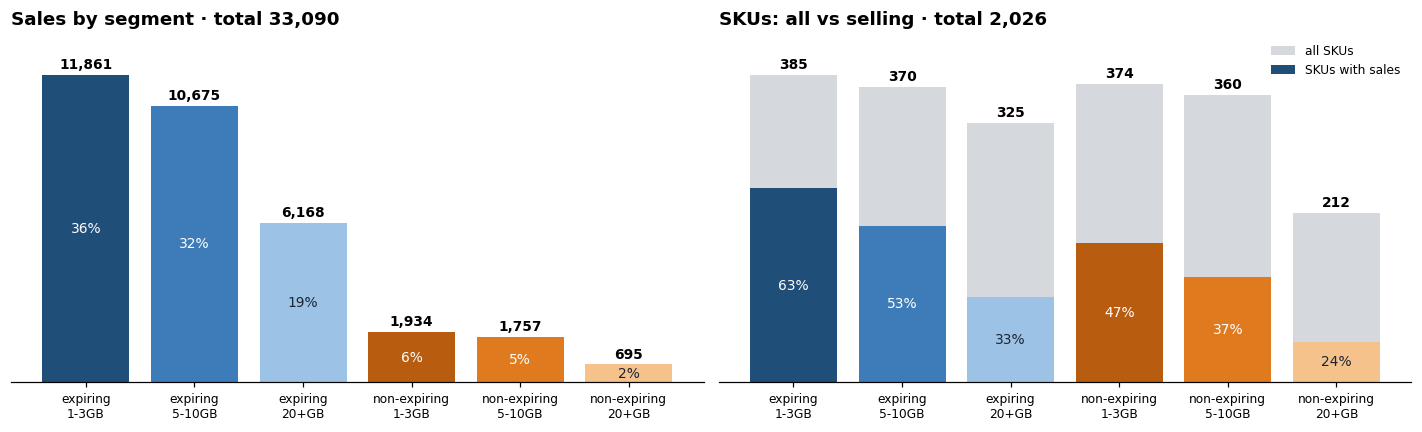

,sku,selling_sku,qty,qty_share
segment,,,,
expiring | 1-3GB,385,243,11861,0.36
expiring | 5-10GB,370,196,10675,0.32
expiring | 20+GB,325,107,6168,0.19
non-expiring | 1-3GB,374,174,1934,0.06
non-expiring | 5-10GB,360,132,1757,0.05
non-expiring | 20+GB,212,51,695,0.02
unlimited | Unlimited,322,0,0,0.00


In [3]:
seg = df.groupby("segment").agg(sku=("qty", "size"), selling_sku=("qty", lambda s: int((s > 0).sum())), qty=("qty", "sum"))
seg = seg.reindex(SEGMENTS + ["unlimited | Unlimited"]).fillna(0)
seg["qty_share"] = seg["qty"] / TOTAL_QTY
cum = df["qty"].sort_values(ascending=False).cumsum() / TOTAL_QTY
n80 = int((cum < 0.8).sum()) + 1

s6 = seg.loc[SEGMENTS]
labels = [s.replace(" | ", "\n") for s in SEGMENTS]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bars = ax[0].bar(labels, s6["qty"], color=SEG_COLORS)
ax[0].bar_label(bars, labels=[f"{v:,.0f}" for v in s6["qty"]], fontsize=9, fontweight="bold", padding=2)
for bar, sh, c in zip(bars, s6["qty_share"], SEG_COLORS):
    ax[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f"{sh:.0%}", ha="center", va="center", fontsize=9, color=ink(c))
ax[0].set_title(f"Sales by segment · total {TOTAL_QTY:,.0f}")
b_all = ax[1].bar(labels, s6["sku"], color="#D5D8DC", label="all SKUs")
b_sel = ax[1].bar(labels, s6["selling_sku"], color=SEG_COLORS, label="SKUs with sales")
ax[1].bar_label(b_all, labels=[f"{v:,.0f}" for v in s6["sku"]], fontsize=9, fontweight="bold", padding=2)
for bar, sel, tot, c in zip(b_sel, s6["selling_sku"], s6["sku"], SEG_COLORS):
    ax[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f"{sel / tot:.0%}", ha="center", va="center", fontsize=9, color=ink(c))
ax[1].set_title(f"SKUs: all vs selling · total {int(s6['sku'].sum()):,}"); ax[1].legend(fontsize=8, frameon=False)
for a_ in ax:
    clean_axis(a_, "y"); a_.tick_params(axis="x", labelsize=8); a_.set_ylim(0, a_.get_ylim()[1] * 1.08)
show("sales_by_segment")
seg

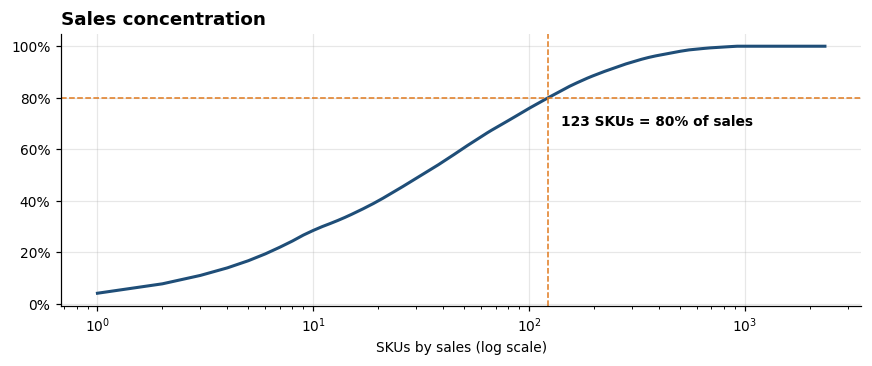

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(np.arange(1, len(cum) + 1), cum.to_numpy(), color="#1F4E78", lw=2); ax.set_xscale("log")
ax.axvline(n80, color="#E07A1F", ls="--", lw=1); ax.axhline(0.8, color="#E07A1F", ls="--", lw=1)
ax.annotate(f"{n80} SKUs = 80% of sales", (n80, 0.8), xytext=(8, -18), textcoords="offset points", fontsize=9, fontweight="bold")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set(title="Sales concentration", xlabel="SKUs by sales (log scale)", ylabel="")
show("sales_concentration")

In [5]:
exp_share = seg.loc[SEGMENTS[:3], "qty"].sum() / TOTAL_QTY
noexp_share = seg.loc[SEGMENTS[3:], "qty"].sum() / TOTAL_QTY
say(f'''
**Finding.** {TOTAL_QTY:,.0f} packs sold. {int((df["qty"] > 0).sum())} of {len(df):,} SKUs have sales, and {n80} SKUs make 80% of sales.
Expiring packs — **{pct(exp_share)}** of sales (1–3 GB — {pct(seg.loc["expiring | 1-3GB", "qty_share"])}, 5–10 GB — {pct(seg.loc["expiring | 5-10GB", "qty_share"])}, 20+ GB — {pct(seg.loc["expiring | 20+GB", "qty_share"])}),
non-expiring — {pct(noexp_share)}, Unlimited — {seg.loc["unlimited | Unlimited", "qty"]:,.0f} sales.

→ The main pricing field is expiring packs. All totals below are **sales-weighted**, not per SKU:
a position without sales must not weigh as much as one with a thousand sales.
''')


**Finding.** 33,090 packs sold. 903 of 2,348 SKUs have sales, and 123 SKUs make 80% of sales.
Expiring packs — **87%** of sales (1–3 GB — 36%, 5–10 GB — 32%, 20+ GB — 19%),
non-expiring — 13%, Unlimited — 0 sales.

→ The main pricing field is expiring packs. All totals below are **sales-weighted**, not per SKU:
a position without sales must not weigh as much as one with a thousand sales.


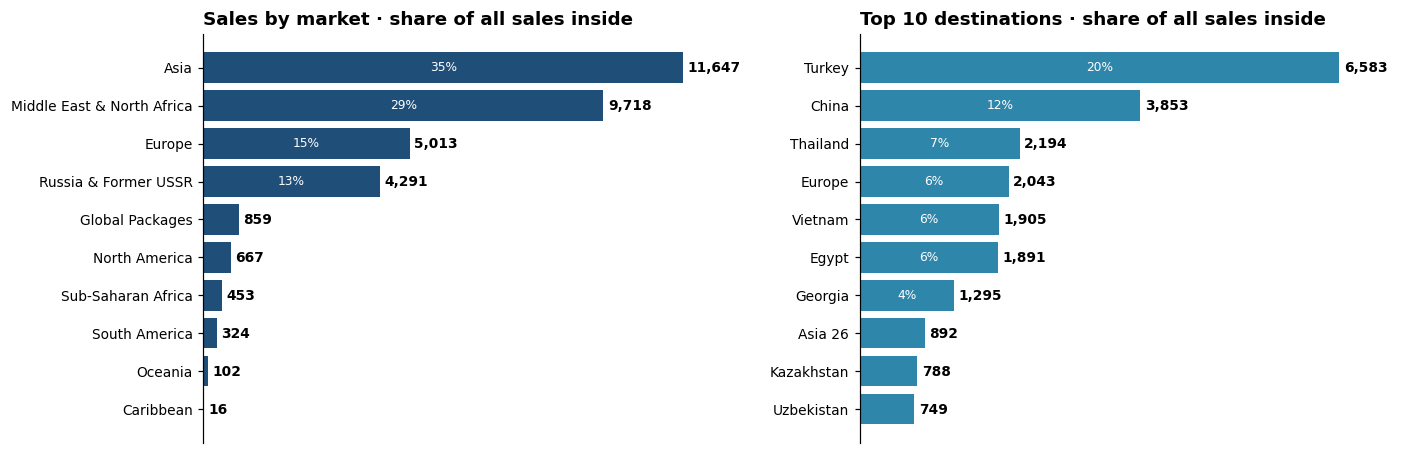


**Finding.** The two largest markets — Asia and Middle East & North Africa — make 65% of sales.
The top destination is Turkey (20%); the top 10 destinations make 67%.


In [6]:
mk = df.groupby("market")["qty"].sum().sort_values(ascending=False).to_frame("sales")
mk["share"] = mk["sales"] / TOTAL_QTY
top_reg = df.groupby("region")["qty"].sum().nlargest(10).to_frame("sales")
top_reg["share"] = top_reg["sales"] / TOTAL_QTY

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a_, data, color, title in [(ax[0], mk, "#1F4E78", "Sales by market"), (ax[1], top_reg, "#2E86AB", "Top 10 destinations")]:
    d = data[::-1]
    bars = a_.barh(d.index, d["sales"], color=color)
    a_.bar_label(bars, labels=[f"{v:,.0f}" for v in d["sales"]], padding=3, fontsize=9, fontweight="bold")
    for bar, sh in zip(bars, d["share"]):
        if sh >= 0.03:
            a_.text(bar.get_width() / 2, bar.get_y() + bar.get_height() / 2, f"{sh:.0%}", ha="center", va="center", fontsize=8, color="white")
    a_.set_xlim(0, d["sales"].max() * 1.15); clean_axis(a_, "x"); a_.set_title(f"{title} · share of all sales inside")
show("sales_by_market")
say(f'''
**Finding.** The two largest markets — {mk.index[0]} and {mk.index[1]} — make {pct(mk["share"].iloc[:2].sum())} of sales.
The top destination is {top_reg.index[0]} ({pct(top_reg["share"].iloc[0])}); the top 10 destinations make {pct(top_reg["share"].sum())}.
''')

## 1.3 Competitor prices: coverage and quality

In [7]:
comps = ["c1", "c2", "c3"]
for k in (1, 2, 3):
    a = pd.to_numeric(raw[f"comp{k}"], errors="coerce")
    b = pd.to_numeric(raw[f"_comp{k}"], errors="coerce")
    df[f"c{k}"] = a.where(a > 0, b.where(b > 0))     # _compN is a second source of compN
comp_raw = df[comps].copy()                          # raw prices, kept for re-runs of the cleaning cell

has_raw = df[comps].notna().any(axis=1)
cover = df.assign(has=has_raw, qty_has=df["qty"] * has_raw).groupby("segment")[["qty", "qty_has"]].sum().reindex(SEGMENTS)
cover["share of sales with competitor prices"] = cover["qty_has"] / cover["qty"]
n_noexp_comp = int(has_raw[df["plan"] == "non-expiring"].sum())
cover

,qty,qty_has,share of sales with competitor prices
segment,,,
expiring | 1-3GB,11861,11375,0.96
expiring | 5-10GB,10675,10353,0.97
expiring | 20+GB,6168,6058,0.98
non-expiring | 1-3GB,1934,0,0.00
non-expiring | 5-10GB,1757,3,0.00
non-expiring | 20+GB,695,0,0.00


In [8]:
pairs_cost = df[(df["plan"] == "expiring") & (df["validity"] == PAIR_VALIDITY)].merge(
    df[df["plan"] == "non-expiring"], on=["region", "vol"], suffixes=("_exp", "_noexp"))
cost_ratio = (pairs_cost["cost_noexp"] / pairs_cost["cost_exp"]).groupby(pairs_cost["vol"]).median()
say(f'''
**Finding.** Competitor prices exist for {pct(cover.loc[SEGMENTS[:3], "qty_has"].sum() / cover.loc[SEGMENTS[:3], "qty"].sum())} of expiring-pack sales
and for only {n_noexp_comp} non-expiring SKUs. A non-expiring pack costs us more than the {PAIR_VALIDITY}-day pack of the same volume, by {pct(cost_ratio.median() - 1)} on average ({pct(cost_ratio.min() - 1)} to {pct(cost_ratio.max() - 1)} across volumes).

→ **Rule 1.** Prices are decided on expiring packs; non-expiring prices are **derived** from the {PAIR_VALIDITY}-day pack of the same region and volume:
`non-expiring price = max(margin parity, min(+premium, +{NOEXP_MAX_EUR:.0f} €))`. Premium by volume — `NOEXP_PREMIUM` ({pct(min(NOEXP_PREMIUM.values()))} to {pct(max(NOEXP_PREMIUM.values()))}).
It is not below the cost difference, so the non-expiring pack keeps its margin, and the EUR cap
keeps the gap from looking like a mark-up.
''')
pd.DataFrame({"cost non-expiring / expiring": cost_ratio, "premium NOEXP_PREMIUM": pd.Series(NOEXP_PREMIUM)}).dropna()


**Finding.** Competitor prices exist for 97% of expiring-pack sales
and for only 2 non-expiring SKUs. A non-expiring pack costs us more than the 30-day pack of the same volume, by 25% on average (24% to 27% across volumes).

→ **Rule 1.** Prices are decided on expiring packs; non-expiring prices are **derived** from the 30-day pack of the same region and volume:
`non-expiring price = max(margin parity, min(+premium, +20 €))`. Premium by volume — `NOEXP_PREMIUM` (25% to 40%).
It is not below the cost difference, so the non-expiring pack keeps its margin, and the EUR cap
keeps the gap from looking like a mark-up.


,cost non-expiring / expiring,premium NOEXP_PREMIUM
1.00,1.25,0.25
3.00,1.27,0.25
5.00,1.24,0.25
10.00,1.25,0.30
20.00,1.25,0.30
50.00,1.25,0.40
100.00,1.27,0.40


Cleaning: competitor prices are not used for non-expiring packs; outliers are removed.

In [9]:
df[comps] = comp_raw                                 # start from raw prices, so the cell can be re-run safely
before = comp_raw.copy()
df.loc[df["plan"] == "non-expiring", comps] = np.nan

n = df[comps].notna().sum(axis=1)
ratio = df[comps].div(df[comps].median(axis=1), axis=0)
outlier3 = (n >= 3).to_numpy()[:, None] & ((ratio > OUTLIER_X) | (ratio < 1 / OUTLIER_X)).to_numpy()
df[comps] = df[comps].mask(outlier3)

two = df[comps].notna().sum(axis=1).eq(2) & (df[comps].max(axis=1) / df[comps].min(axis=1) > OUTLIER_X)
dist = np.log(df.loc[two, comps].div(df.loc[two, "target_price"], axis=0)).abs()
for i, col in dist.idxmax(axis=1).items():
    df.loc[i, col] = np.nan

removed = before.notna() & df[comps].isna()
worst = (before[removed].max(axis=1) / df["target_price"]).max()
say(f'''
**Finding.** Competitor prices removed: {int(removed.sum().sum())} (positions with {pct(df.loc[removed.any(axis=1), "qty"].sum() / TOTAL_QTY, 1)} of sales).
The most extreme one is {worst:.0f}x our target-margin price.

→ **Rule 0.** A price more than `OUTLIER_X` = {OUTLIER_X:g}x away from the other prices in the row is a data error.
''')


**Finding.** Competitor prices removed: 41 (positions with 5.7% of sales).
The most extreme one is 46x our target-margin price.

→ **Rule 0.** A price more than `OUTLIER_X` = 3x away from the other prices in the row is a data error.


In [10]:
srt = np.sort(df[comps].to_numpy(), axis=1)
df["n_comp"] = df[comps].notna().sum(axis=1)
df["has_comp"] = df["n_comp"] > 0
df["best"] = srt[:, 0]
df["second"] = np.where(df["n_comp"] >= 2, srt[:, 1], df["best"])
df["median_comp"] = df[comps].median(axis=1)
QTY_COMP = df.loc[df["has_comp"], "qty"].sum()
say(f"After cleaning, competitor prices exist for **{int(df['has_comp'].sum()):,} SKUs** — {pct(QTY_COMP / TOTAL_QTY)} of all sales. "
    f"All 'TOP-1 / in market' shares below are computed on these sales.")

After cleaning, competitor prices exist for **1,005 SKUs** — 84% of all sales. All 'TOP-1 / in market' shares below are computed on these sales.

## 1.4 Where we stand versus the market

Only sales with competitor prices. We compare the best competitor and the competitor median with our cost and with our target-margin price.

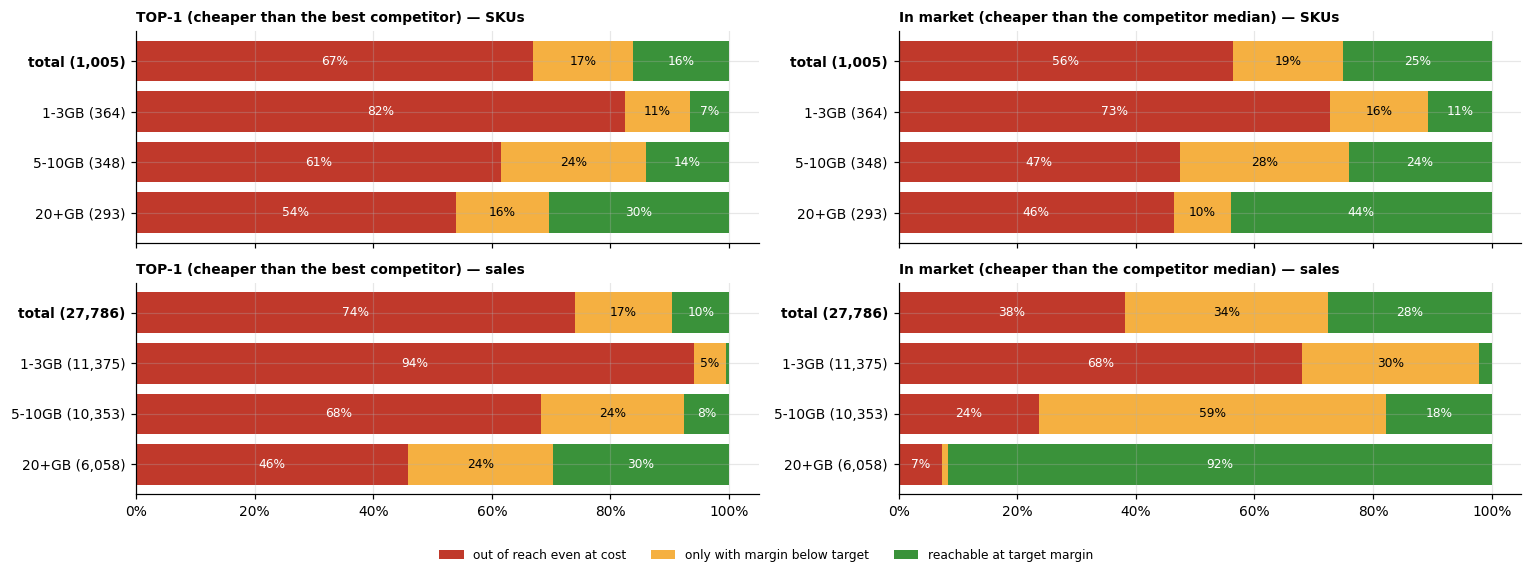

TOP-1, sales                                \
zone_top1 out of reach even at cost only with margin below target   
total                         20545                          4586   
1-3GB                         10693                           622   
5-10GB                         7071                          2488   
20+GB                          2781                          1476   

                                              in market, sales  \
zone_top1 reachable at target margin out of reach even at cost   
total                           2655                     10626   
1-3GB                             60                      7741   
5-10GB                           794                      2445   
20+GB                           1801                       440   

                                                                    
zone_top1 only with margin below target reachable at target margin  
total                              9510                       7650  
1-3GB                              3382                        252  
5-10GB                             6060                       1848  
20+GB                                68                       5550

,best competitor < our cost,best competitor < our target price,competitor median < our cost,competitor median < our target price
bucket,,,,
1-3GB,94%,99%,68%,98%
5-10GB,68%,92%,24%,82%
20+GB,46%,70%,7%,8%
total,74%,90%,38%,72%


In [11]:
x = df[df["has_comp"]].copy()
x["best_lt_cost"] = x["best"] < x["cost"]
x["best_lt_target"] = x["best"] < x["target_price"]
x["median_lt_cost"] = x["median_comp"] < x["cost"]
x["median_lt_target"] = x["median_comp"] < x["target_price"]
x["median_gt_target"] = x["median_comp"] >= x["target_price"]

def sales_share(frame, flag, by=None):
    w = frame["qty"] * frame[flag]
    if by is None:
        return w.sum() / frame["qty"].sum()
    return w.groupby(frame[by]).sum() / frame.groupby(by)["qty"].sum()

level = pd.DataFrame({
    "best competitor < our cost": sales_share(x, "best_lt_cost", "bucket"),
    "best competitor < our target price": sales_share(x, "best_lt_target", "bucket"),
    "competitor median < our cost": sales_share(x, "median_lt_cost", "bucket"),
    "competitor median < our target price": sales_share(x, "median_lt_target", "bucket"),
})
level.loc["total"] = [sales_share(x, f) for f in ["best_lt_cost", "best_lt_target", "median_lt_cost", "median_lt_target"]]
level = level.reindex([b for b in BUCKETS if b in level.index] + ["total"])

# where can we reach the market at all? competitor level vs our cost and our target price
ZONES = ["out of reach even at cost", "only with margin below target", "reachable at target margin"]
ZONE_COLORS = ["#C0392B", "#F5B041", "#3A923A"]

def zone(comp):
    return pd.Series(np.select([comp < x["cost"], comp < x["target_price"]], ZONES[:2], ZONES[2]), index=x.index)

x["zone_top1"] = zone(x["best"])           # TOP-1: be cheaper than the best competitor
x["zone_market"] = zone(x["median_comp"])  # in market: be cheaper than the median

def zone_table(col, weight=None):
    rows = {"total": x}
    rows.update({bk: x[x["bucket"] == bk] for bk in BUCKETS if (x["bucket"] == bk).any()})
    out = {}
    for name, g in rows.items():
        w = g["qty"] if weight == "qty" else pd.Series(1, index=g.index)
        out[name] = w.groupby(g[col]).sum().reindex(ZONES, fill_value=0)
    return pd.DataFrame(out).T

fig, axes = plt.subplots(2, 2, figsize=(14, 5.2), sharex=True)
for i, (weight, wname) in enumerate([(None, "SKUs"), ("qty", "sales")]):
    for j, (col, goal) in enumerate([("zone_top1", "TOP-1 (cheaper than the best competitor)"),
                                     ("zone_market", "In market (cheaper than the competitor median)")]):
        ax, t = axes[i, j], zone_table(col, weight)
        share, left = t.div(t.sum(axis=1), axis=0), np.zeros(len(t))
        for z, color in zip(ZONES, ZONE_COLORS):
            ax.barh(t.index, share[z], left=left, color=color, label=z)
            for y, (l, v, n_) in enumerate(zip(left, share[z], t[z])):
                if v > 0.05:
                    ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if z != ZONES[1] else "black")
            left += share[z].to_numpy()
        ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
        ax.set_yticks(range(len(t)), [f"{n} ({t.loc[n].sum():,.0f})" for n in t.index])
        ax.get_yticklabels()[0].set_fontweight("bold")
        ax.set_title(f"{goal} — {wname}", fontsize=9)
h_, l_ = axes[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, ncol=3, fontsize=8, loc="lower center", frameon=False)
show("reach_at_cost", rect=[0, 0.06, 1, 1])
display(pd.concat({"TOP-1, sales": zone_table("zone_top1", "qty"), "in market, sales": zone_table("zone_market", "qty")}, axis=1))
level.style.format("{:.0%}").set_caption("Share of sales with competitor prices")

In [12]:
in_market_at_target = 1 - level.loc["total", "competitor median < our target price"]
room_up = x.loc[x["median_gt_target"]]
room_share = room_up["qty"].sum() / x["qty"].sum()
room_10 = sales_share(x, "median_gt_target", "bucket").get("20+GB", np.nan)
max_ratio = (x["median_comp"] / x["target_price"]).max()
say(f'''
**Findings.**
- If we simply price at target margin, only **{pct(in_market_at_target)}** of sales are in market (cheaper than the competitor median).
- For **{pct(level.loc["total", "best competitor < our cost"])}** of sales even the best competitor is cheaper than our cost:
  TOP-1 there is only possible at a loss: 1–3 GB — {pct(level.loc["1-3GB", "best competitor < our cost"])}, 5–10 GB — {pct(level.loc["5-10GB", "best competitor < our cost"])}, 20+ GB — {pct(level.loc["20+GB", "best competitor < our cost"])}.
- For **{pct(level.loc["total", "competitor median < our cost"])}** of sales even the competitor median is below our cost
  (1–3 GB — {pct(level.loc["1-3GB", "competitor median < our cost"])}, 5–10 GB — {pct(level.loc["5-10GB", "competitor median < our cost"])}, 20+ GB — {pct(level.loc["20+GB", "competitor median < our cost"])}):
  we cannot get in market there without selling at a loss. This is a procurement issue.
- On the other hand, for **{pct(room_share)}** of sales the competitor median is above our target price (20+ GB packs — {pct(room_10)}).
  There we can raise the price and stay in market.

→ **Rule 2.** Target margin is held **for the group as a whole**, not for every SKU. Some positions go below target margin to be in market,
and this is funded where the market allows a higher price. The minimum SKU margin is a scenario parameter
({"; ".join(f"{c['name'].lower()}: {floor_desc(c)}" for c in CASES.values())}).

→ **Rule 3.** Where we are already in market, the price goes up close to the reference (max margin while keeping the status),
but never above `CAP_VS_TARGET` = {CAP_VS_TARGET:g}x the target-margin price. Without a cap, market outliers
(the median reaches {max_ratio:.1f}x our target price) would produce unreasonable prices.
''')


**Findings.**
- If we simply price at target margin, only **28%** of sales are in market (cheaper than the competitor median).
- For **74%** of sales even the best competitor is cheaper than our cost:
  TOP-1 there is only possible at a loss: 1–3 GB — 94%, 5–10 GB — 68%, 20+ GB — 46%.
- For **38%** of sales even the competitor median is below our cost
  (1–3 GB — 68%, 5–10 GB — 24%, 20+ GB — 7%):
  we cannot get in market there without selling at a loss. This is a procurement issue.
- On the other hand, for **28%** of sales the competitor median is above our target price (20+ GB packs — 92%).
  There we can raise the price and stay in market.

→ **Rule 2.** Target margin is held **for the group as a whole**, not for every SKU. Some positions go below target margin to be in market,
and this is funded where the market allows a higher price. The minimum SKU margin is a scenario parameter
(conservative: min SKU margin 15%; medium: min SKU margin 5%; aggressive: min SKU margin −5%).

→ **Rule 3.** Where we are already in market, the price goes up close to the reference (max margin while keeping the status),
but never above `CAP_VS_TARGET` = 2x the target-margin price. Without a cap, market outliers
(the median reaches 4.1x our target price) would produce unreasonable prices.


## 1.4b Top SKUs and destinations in detail

**Top 20 SKUs make 40% of all sales.** At target margin, 6 of them are in market and 7 cannot get there even at cost.

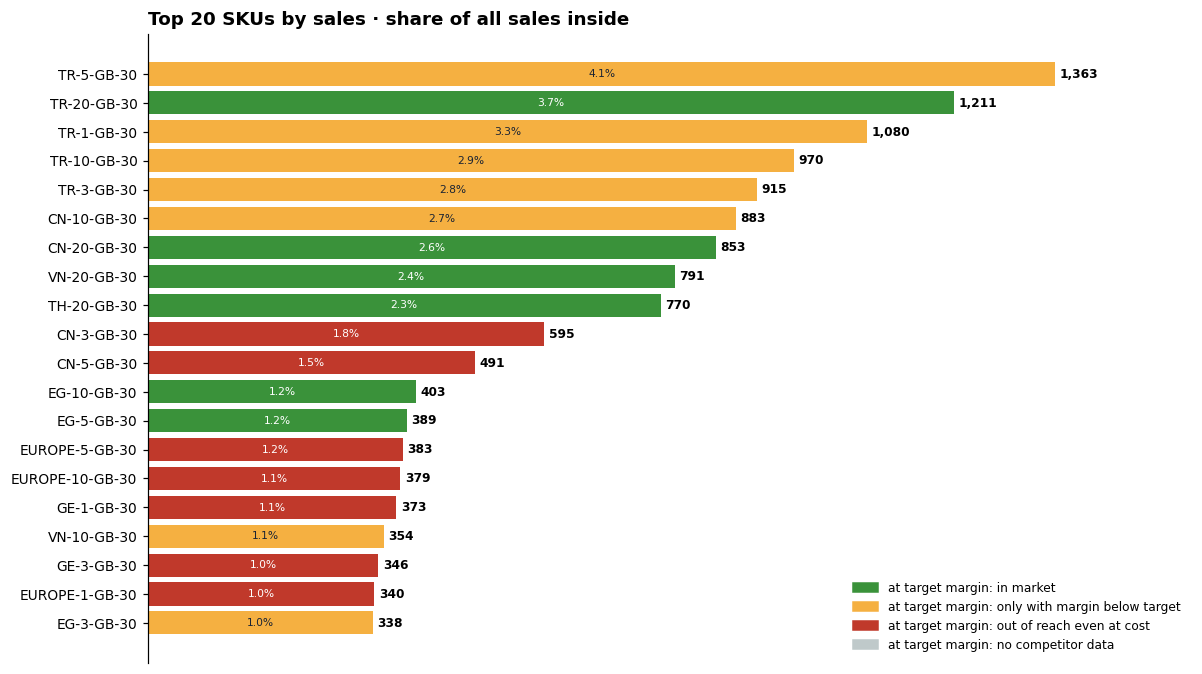

sku,region,segment,qty,cost,target_price,best,median_comp,share of sales,cumulative,target / median,at target margin
TR-5-GB-30,Turkey,expiring | 5-10GB,"1,363",2.17,3.10,1.76,2.70,4.1%,4%,1.15,only with margin below target
TR-20-GB-30,Turkey,expiring | 20+GB,"1,211",7.34,9.18,7.04,10.81,3.7%,8%,0.85,in market
TR-1-GB-30,Turkey,expiring | 1-3GB,"1,080",0.51,0.73,0.35,0.54,3.3%,11%,1.36,only with margin below target
TR-10-GB-30,Turkey,expiring | 5-10GB,970,3.99,5.70,3.52,4.46,2.9%,14%,1.28,only with margin below target
TR-3-GB-30,Turkey,expiring | 1-3GB,915,1.42,2.03,1.06,1.62,2.8%,17%,1.25,only with margin below target
CN-10-GB-30,China,expiring | 5-10GB,883,4.51,6.44,4.13,6.07,2.7%,19%,1.06,only with margin below target
CN-20-GB-30,China,expiring | 20+GB,853,7.51,9.39,7.78,12.14,2.6%,22%,0.77,in market
VN-20-GB-30,Vietnam,expiring | 20+GB,791,6.76,8.45,8.45,12.32,2.4%,24%,0.69,in market
TH-20-GB-30,Thailand,expiring | 20+GB,770,6.76,8.45,5.76,12.32,2.3%,27%,0.69,in market
CN-3-GB-30,China,expiring | 1-3GB,595,2.25,3.22,1.61,1.82,1.8%,29%,1.77,out of reach even at cost


In [13]:
top20 = df.nlargest(20, "qty")[["sku", "region", "segment", "qty", "cost", "target_price", "best", "median_comp"]].copy()
top20["share of sales"] = top20["qty"] / TOTAL_QTY
top20["cumulative"] = top20["share of sales"].cumsum()
top20["target / median"] = top20["target_price"] / top20["median_comp"]
top20["at target margin"] = np.select([top20["median_comp"].isna(), top20["median_comp"] < top20["cost"], top20["target_price"] <= top20["median_comp"] - 0.01],
                                      ["no competitor data", "out of reach even at cost", "in market"], "only with margin below target")
say(f"**Top 20 SKUs make {pct(top20['share of sales'].sum())} of all sales.** "
    f"At target margin, {int((top20['at target margin'] == 'in market').sum())} of them are in market and "
    f"{int((top20['at target margin'] == 'out of reach even at cost').sum())} cannot get there even at cost.")
zone_color = {"in market": "#3A923A", "only with margin below target": "#F5B041", "out of reach even at cost": "#C0392B", "no competitor data": "#BFC9CA"}
fig, ax = plt.subplots(figsize=(11, 6.2))
d = top20[::-1]
bars = ax.barh(d["sku"], d["qty"], color=[zone_color[z] for z in d["at target margin"]])
ax.bar_label(bars, labels=[f"{q:,.0f}" for q in d["qty"]], padding=3, fontsize=8, fontweight="bold")
for bar, sh, z in zip(bars, d["share of sales"], d["at target margin"]):
    ax.text(bar.get_width() / 2, bar.get_y() + bar.get_height() / 2, f"{sh:.1%}", ha="center", va="center", fontsize=7, color=ink(zone_color[z]))
ax.set_xlim(0, d["qty"].max() * 1.15); clean_axis(ax, "x")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in zone_color.values()]
ax.legend(handles, [f"at target margin: {z}" for z in zone_color], fontsize=8, frameon=False, loc="lower right")
ax.set_title("Top 20 SKUs by sales · share of all sales inside")
show("top20_skus")
top20.style.format({"qty": "{:,.0f}", "cost": "{:.2f}", "target_price": "{:.2f}", "best": "{:.2f}", "median_comp": "{:.2f}",
                    "share of sales": "{:.1%}", "cumulative": "{:.0%}", "target / median": "{:.2f}"}, na_rep="—").hide(axis="index")

For analysts: where exactly does our cost lose to the market? Best competitor ÷ our cost by destination and pack size (30-day packs). Below 1.00 — the competitor sells cheaper than we buy.

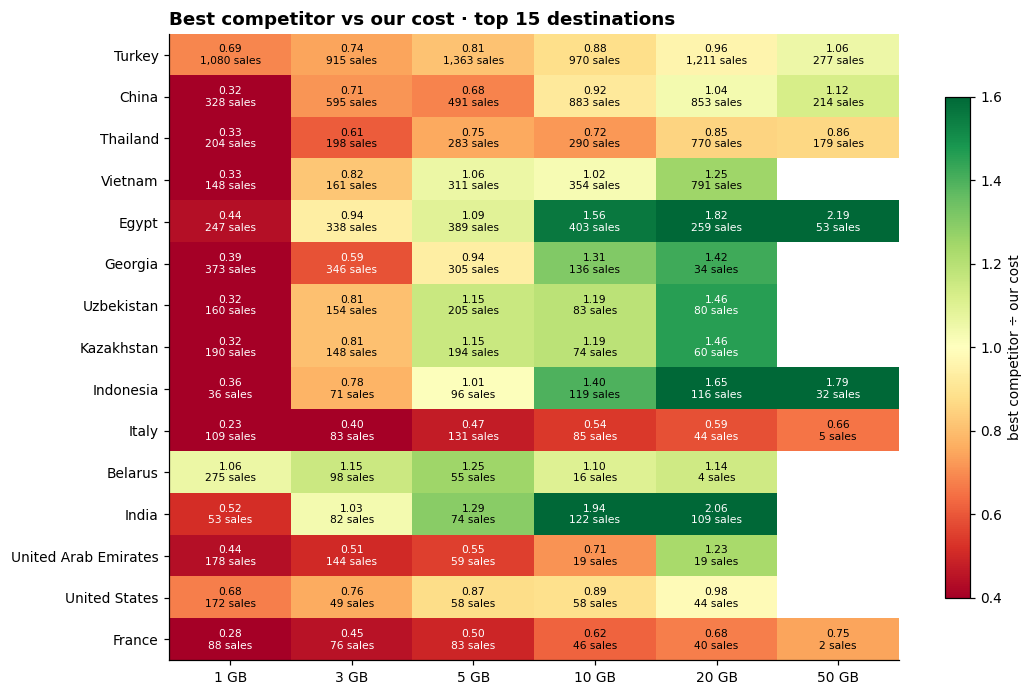

In **Thailand** 100% of sales are in cells where the best competitor is below our cost; in **Belarus** only 0%. Small packs (1–3 GB) are red almost everywhere, 20 GB packs are mostly green.

In [14]:
loc = df[(df["plan"] == "expiring") & (df["validity"] == PAIR_VALIDITY) & df["has_comp"]
         & ~df["subregion"].isin(["Regional Packages", "Global Packages"])].copy()
loc["best_vs_cost"] = loc["best"] / loc["cost"]
top_d = loc.groupby("region")["qty"].sum().nlargest(15).index
vols = [1, 3, 5, 10, 20, 50]
hm = loc[loc["region"].isin(top_d)].pivot_table(index="region", columns="vol", values="best_vs_cost", aggfunc="first").reindex(index=top_d, columns=vols)
hq = loc[loc["region"].isin(top_d)].pivot_table(index="region", columns="vol", values="qty", aggfunc="sum").reindex(index=top_d, columns=vols)
fig, ax = plt.subplots(figsize=(10, 6.4))
im_ = ax.imshow(hm.to_numpy(dtype=float), cmap="RdYlGn", vmin=0.4, vmax=1.6, aspect="auto")
for (r, c), v in np.ndenumerate(hm.to_numpy(dtype=float)):
    if not np.isnan(v):
        ax.text(c, r, f"{v:.2f}\n{hq.iat[r, c]:,.0f} sales", ha="center", va="center", fontsize=7,
                color="white" if (v < 0.6 or v > 1.45) else "black")
ax.set_xticks(range(len(vols)), [f"{v} GB" for v in vols]); ax.set_yticks(range(len(top_d)), top_d); ax.grid(False)
plt.colorbar(im_, ax=ax, shrink=0.8, label="best competitor ÷ our cost")
ax.set_title("Best competitor vs our cost · top 15 destinations")
show("heatmap_best_vs_cost")
worst = (hq * (hm < 1)).sum(axis=1) / hq.sum(axis=1)
say(f"In **{worst.idxmax()}** {pct(worst.max())} of sales are in cells where the best competitor is below our cost; "
    f"in **{worst.idxmin()}** only {pct(worst.min())}. Small packs (1–3 GB) are red almost everywhere, 20 GB packs are mostly green.")

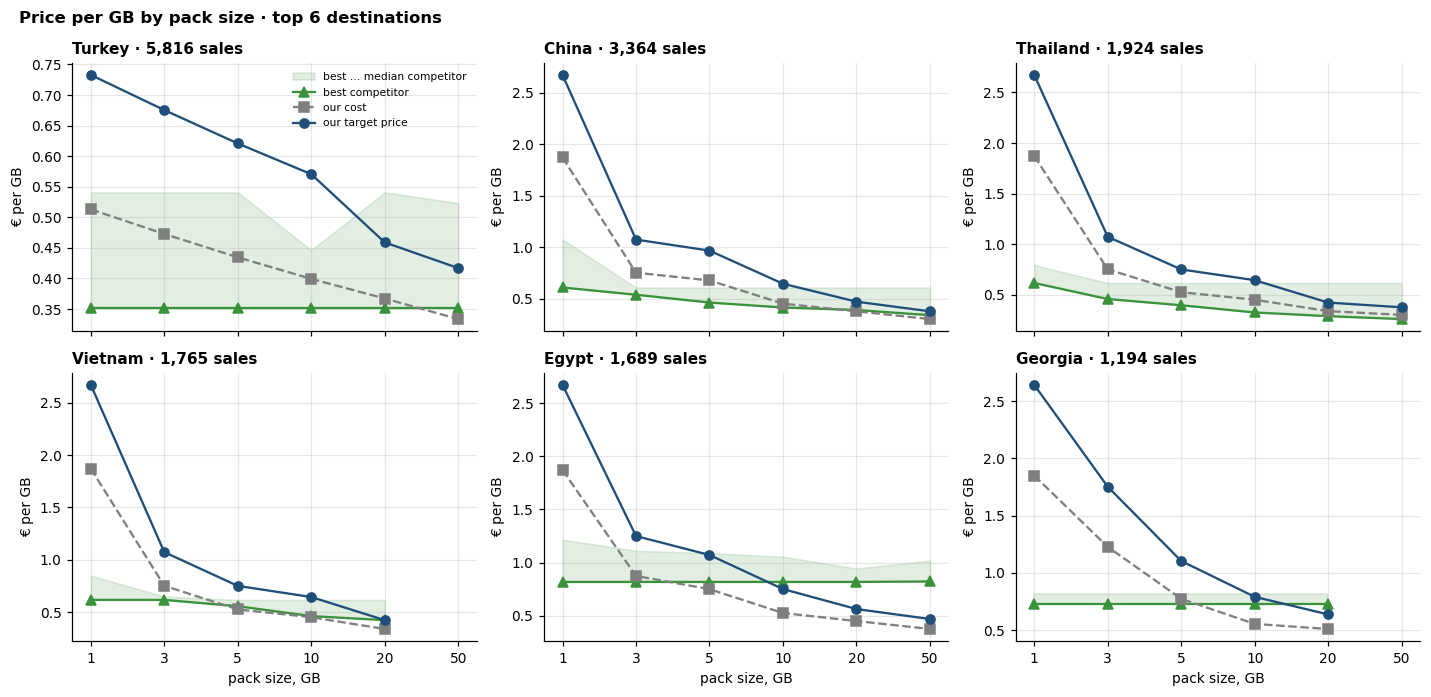

In [15]:
# price per GB by pack size: our cost and target price vs the market
top6 = loc.groupby("region")["qty"].sum().nlargest(6).index
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True)
for ax, rg in zip(axes.ravel(), top6):
    d = loc[(loc["region"] == rg) & loc["vol"].isin(vols)].sort_values("vol")
    xs = [f"{v:.0f}" for v in d["vol"]]
    ax.fill_between(xs, d["best"] / d["vol"], d["median_comp"] / d["vol"], color="#3A923A", alpha=0.15, label="best … median competitor")
    ax.plot(xs, d["best"] / d["vol"], "^-", color="#3A923A", label="best competitor")
    ax.plot(xs, d["cost"] / d["vol"], "s--", color="#7F7F7F", label="our cost")
    ax.plot(xs, d["target_price"] / d["vol"], "o-", color="#1F4E78", label="our target price")
    ax.set_title(f"{rg} · {d['qty'].sum():,.0f} sales", fontsize=10); ax.set_ylabel("€ per GB")
for ax in axes[-1]: ax.set_xlabel("pack size, GB")
axes.ravel()[0].legend(fontsize=7, frameon=False)
fig.suptitle("Price per GB by pack size · top 6 destinations", fontweight="bold", x=0.01, ha="left")
show("price_per_gb_top6")

## 1.5 Which competitor to follow

In [16]:
drop_best = (1 - x["best"] / x["target_price"]).clip(lower=0)        # needed price cut vs target price
drop_second = (1 - x["second"] / x["target_price"]).clip(lower=0)
need = pd.DataFrame({
    "below best": [sales_share(x.assign(f=x["best"] < x["target_price"]), "f"), np.average(drop_best[drop_best > 0], weights=x.loc[drop_best > 0, "qty"] + 1e-9)],
    "below second": [sales_share(x.assign(f=x["second"] < x["target_price"]), "f"), np.average(drop_second[drop_second > 0], weights=x.loc[drop_second > 0, "qty"] + 1e-9)],
}, index=["sales that need a price cut", "average cut needed (sales-weighted)"])
gap = (x["second"] / x["best"]).median()
say(f'''
**Finding.** To be cheaper than the **best** competitor we would have to cut the price for {pct(need.loc["sales that need a price cut", "below best"])} of sales,
by {pct(need.loc["average cut needed (sales-weighted)", "below best"])} on average. To be no more expensive than the **second** one —
for {pct(need.loc["sales that need a price cut", "below second"])}, by {pct(need.loc["average cut needed (sales-weighted)", "below second"])} on average.
The second competitor is {pct(gap - 1)} more expensive than the best one on average.

→ **Rule 4.** Three scenarios that differ in the reference competitor and in the minimum SKU margin:
''')
pd.DataFrame([{"scenario": f"{k}. {c['name']}", "SKU floor": floor_desc(c),
               "reference": "second competitor" if c["target"] == "second" else "best competitor"} for k, c in CASES.items()])


**Finding.** To be cheaper than the **best** competitor we would have to cut the price for 90% of sales,
by 46% on average. To be no more expensive than the **second** one —
for 71%, by 37% on average.
The second competitor is 18% more expensive than the best one on average.

→ **Rule 4.** Three scenarios that differ in the reference competitor and in the minimum SKU margin:


,scenario,SKU floor,reference
0,1. Conservative,min SKU margin 15%,second competitor
1,2. Medium,min SKU margin 5%,best competitor
2,3. Aggressive,min SKU margin −5%,best competitor


In [17]:
say(f'''
**Market position metrics** (share of sales with competitor prices):
- **TOP-1** — we are the cheapest;
- **TOP-2** — not more expensive than the second competitor;
- **in market** — cheaper than the competitor median.

TOP-1 ⊂ in market ⊂ TOP-2.

→ **Rule 5.** We maximise sales at the scenario target and additionally count sales in market with weight
`IN_MARKET_WEIGHT` = {IN_MARKET_WEIGHT:g}. With this weight TOP-1 gives {1 + IN_MARKET_WEIGHT:g} points per sale, and in market alone — {IN_MARKET_WEIGHT:g}.
''')


**Market position metrics** (share of sales with competitor prices):
- **TOP-1** — we are the cheapest;
- **TOP-2** — not more expensive than the second competitor;
- **in market** — cheaper than the competitor median.

TOP-1 ⊂ in market ⊂ TOP-2.

→ **Rule 5.** We maximise sales at the scenario target and additionally count sales in market with weight
`IN_MARKET_WEIGHT` = 1. With this weight TOP-1 gives 2 points per sale, and in market alone — 1.


## 1.6 Price format and volume ladder

In [18]:
def to_x9(p, how="nearest"):
    k = (np.asarray(p, dtype=float) + 0.01) / PRICE_STEP
    k = np.floor(k + 1e-9) if how == "down" else np.ceil(k - 1e-9) if how == "up" else np.round(k)
    return np.round(k * PRICE_STEP - 0.01, 2)

ladder_mask = (df["bucket"] != "Unlimited") & df["vol"].notna()

def ladder_table(price):
    t = df.loc[ladder_mask, ["region", "validity", "vol"]].assign(price=np.asarray(price)[ladder_mask.to_numpy()])
    t = t.sort_values(["region", "validity", "vol"])
    g = t.groupby(["region", "validity"])
    t["prev_price"], t["prev_vol"] = g["price"].shift(), g["vol"].shift()
    t["too_cheap"] = t["price"] < t["prev_price"] + PRICE_STEP - 1e-9
    t["too_expensive_per_gb"] = t["price"] > t["prev_price"] * t["vol"] / t["prev_vol"] + PRICE_STEP + 1e-9
    return t

lt = ladder_table(to_x9(df["target_price"]))
cheap = df["target_price"] < 1
say(f'''
**Finding.** With target prices in the X.Y9 format, volume ladder breaks: {int((lt["too_cheap"] | lt["too_expensive_per_gb"]).sum())}.
The format step ({PRICE_STEP:.2f} €) is {pct(PRICE_STEP / df.loc[cheap, "target_price"].median())} of the price for packs below 1 €;
they make {pct(df.loc[cheap, "qty"].sum() / TOTAL_QTY)} of sales.

→ The ladder is checked and fixed at every step: a bigger pack is at least {PRICE_STEP:.2f} € more expensive than a smaller one,
and the price per GB does not grow with volume.
''')


**Finding.** With target prices in the X.Y9 format, volume ladder breaks: 1.
The format step (0.10 €) is 14% of the price for packs below 1 €;
they make 3% of sales.

→ The ladder is checked and fixed at every step: a bigger pack is at least 0.10 € more expensive than a smaller one,
and the price per GB does not grow with volume.


## 1.7 Summary: pricing rules

In [19]:
rules = pd.DataFrame([
    ["0. Data cleaning", f"{int(removed.sum().sum())} outlier prices", f"OUTLIER_X = {OUTLIER_X:g}"],
    ["1. Non-expiring derived from expiring", f"no competitor prices ({n_noexp_comp} SKUs); cost higher by {pct(cost_ratio.median() - 1)}",
     f"NOEXP_PREMIUM {pct(min(NOEXP_PREMIUM.values()))}–{pct(max(NOEXP_PREMIUM.values()))}, NOEXP_MAX_EUR = {NOEXP_MAX_EUR:g}"],
    ["2. Margin per group, not per SKU", f"at target price only {pct(in_market_at_target)} of sales in market", "min_margin per SKU in CASES"],
    ["3. Raise where the market allows", f"median above target price for {pct(room_share)} of sales", f"CAP_VS_TARGET = {CAP_VS_TARGET:g}"],
    ["4. Two references, several SKU floors", f"second competitor {pct(gap - 1)} above the best", f"target in CASES ({len(CASES)} scenarios)"],
    ["5. Weight of 'in market'", "TOP-1 out of reach for most sales", f"IN_MARKET_WEIGHT = {IN_MARKET_WEIGHT:g}"],
], columns=["Rule", "What the data shows", "Parameter"])
rules.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"})

Rule,What the data shows,Parameter
0. Data cleaning,41 outlier prices,OUTLIER_X = 3
1. Non-expiring derived from expiring,no competitor prices (2 SKUs); cost higher by 25%,"NOEXP_PREMIUM 25%–40%, NOEXP_MAX_EUR = 20"
"2. Margin per group, not per SKU",at target price only 28% of sales in market,min_margin per SKU in CASES
3. Raise where the market allows,median above target price for 28% of sales,CAP_VS_TARGET = 2
"4. Two references, several SKU floors",second competitor 18% above the best,target in CASES (3 scenarios)
5. Weight of 'in market',TOP-1 out of reach for most sales,IN_MARKET_WEIGHT = 1


# 2. Scenario calculation

## 2.1 Building blocks

Pairs 'expiring pack → non-expiring pack' and the non-expiring price according to Rule 1.

In [20]:
# 1) pairs used to derive the price: non-expiring <- 30-day pack of the same region and volume
exp30 = df[(df["plan"] == "expiring") & (df["validity"] == PAIR_VALIDITY)].reset_index()[["index", "region", "vol"]]
noexp_rows = df[df["plan"] == "non-expiring"].reset_index()[["index", "region", "vol"]]
pairs = exp30.merge(noexp_rows, on=["region", "vol"], suffixes=("_exp", "_noexp"))
assert pairs["index_noexp"].is_unique, "a non-expiring pack has several 30-day partners"
pairs["premium"] = pairs["vol"].map(NOEXP_PREMIUM)
pairs["parity"] = df.loc[pairs["index_noexp"], "cost"].to_numpy() / df.loc[pairs["index_exp"], "cost"].to_numpy()

# 2) all "expiring vs non-expiring" combinations of the same region and volume (any validity) — for the rule check
exp_any = df[df["plan"] == "expiring"].reset_index()[["index", "region", "vol", "validity"]]
all_pairs = exp_any.merge(noexp_rows, on=["region", "vol"], suffixes=("_exp", "_noexp"))

def noexp_price(p_exp, pr=pairs):
    p = np.maximum(p_exp * pr["parity"].to_numpy(),
                   np.minimum(p_exp * (1 + pr["premium"].to_numpy()), p_exp + NOEXP_MAX_EUR))
    return np.maximum(to_x9(p, "up"), to_x9(p_exp + PRICE_STEP, "up"))

def add_noexp(price):
    price = pd.Series(price, index=df.index, dtype=float).copy()
    price[pairs["index_noexp"]] = noexp_price(price[pairs["index_exp"]].to_numpy())
    # guard: a non-expiring pack is never cheaper than ANY expiring pack (e.g. 7-day) of the same region and volume
    need = (price[all_pairs["index_exp"]].to_numpy() + PRICE_STEP)
    floor_n = pd.Series(need, index=all_pairs["index_noexp"]).groupby(level=0).max()
    price[floor_n.index] = np.maximum(price[floor_n.index], to_x9(floor_n.to_numpy(), "up"))
    return price

n_noexp = int((df["plan"] == "non-expiring").sum())
unpaired = noexp_rows[~noexp_rows["index"].isin(pairs["index_noexp"])].merge(
    exp_any, on=["region", "vol"], how="left", suffixes=("", "_exp"))
say(f'''Pairs "{PAIR_VALIDITY}-day → non-expiring": **{len(pairs)}** of {n_noexp} non-expiring packs.
Without a {PAIR_VALIDITY}-day pair — {n_noexp - len(pairs)}: priced at target margin.
{int(unpaired["validity"].notna().sum())} of them have a pack with another validity
({", ".join(f"{r.region} {r.vol:.0f} GB — {r.validity:.0f} days" for r in unpaired.dropna(subset=["validity"]).itertuples())}):
the non-expiring pack is always at least that pack + {PRICE_STEP:.2f} €.''')

Pairs "30-day → non-expiring": **939** of 946 non-expiring packs.
Without a 30-day pair — 7: priced at target margin.
2 of them have a pack with another validity
(Saint Barthelemy 1 GB — 7 days, Niger 1 GB — 7 days):
the non-expiring pack is always at least that pack + 0.10 €.

Margin budget of a group: `Σ qty × ((1 − target margin) × price − cost)`. If it is ≥ 0, the target margin is met.

In [21]:
def budget(price):
    return (df["qty"] * ((1 - df["target_margin"]) * price - df["cost"])).groupby(df["grp"]).sum()

def margin(price, by="grp"):
    rev = (df["qty"] * price).groupby(df[by]).sum()
    return (df["qty"] * (price - df["cost"])).groupby(df[by]).sum() / rev.replace(0, np.nan)

Ladder fix: walk from the smallest pack to the biggest. Expiring ladders first, then non-expiring ones.

In [22]:
def fix_ladder(price, floor, plan="expiring"):
    price = pd.Series(price, index=df.index, dtype=float).copy()
    floor = pd.Series(floor, index=df.index)
    t = ladder_table(price)
    t = t[(t["validity"] == -1) if plan == "non-expiring" else (t["validity"] != -1)]
    for _, g in t.groupby(["region", "validity"]):
        idx, vols = g.index.to_list(), g["vol"].to_numpy()
        # forward pass (small -> big): bigger pack at least one step dearer; per-GB price not higher (lower the big pack if the floor allows)
        for k in range(1, len(idx)):
            lo, hi = idx[k - 1], idx[k]
            if price[hi] < price[lo] + PRICE_STEP - 1e-9:
                price[hi] = to_x9(price[lo] + PRICE_STEP, "up")
            limit = price[lo] * vols[k] / vols[k - 1] + PRICE_STEP
            if price[hi] > limit + 1e-9 and to_x9(limit, "down") >= floor[hi]:
                price[hi] = to_x9(limit, "down")
        # backward pass (big -> small): where the big pack could not go lower, lift the smaller one
        for k in range(len(idx) - 1, 0, -1):
            lo, hi = idx[k - 1], idx[k]
            need = (price[hi] - PRICE_STEP) * vols[k - 1] / vols[k]
            if price[lo] < need - 1e-9:
                price[lo] = to_x9(need, "up")
    return price

def fix_ladder_all(price, floor, plan, passes=5):
    # repeat until nothing changes: a fix higher up the ladder can create a new break lower down
    for _ in range(passes):
        new = fix_ladder(price, floor, plan)
        if new.equals(price):
            break
        price = new
    return price

def apply_rules(price, floor):
    # expiring ladder -> non-expiring from expiring (never below its own floor) -> non-expiring ladder
    price = add_noexp(fix_ladder_all(price, floor, "expiring"))
    nx = (df["plan"] == "non-expiring").to_numpy()
    price[nx] = np.maximum(price[nx].to_numpy(), pd.Series(floor, index=df.index)[nx].to_numpy())
    return fix_ladder_all(price, floor, "non-expiring")

# quick check on target-margin prices
test = add_noexp(to_x9(df["target_price"]))
n_breaks = lambda p: int(ladder_table(p)[["too_cheap", "too_expensive_per_gb"]].any(axis=1).sum())
fixed = apply_rules(test, to_x9(df["cost"], "up"))
say(f"Check on target prices: ladder breaks before — {n_breaks(test)}, after `apply_rules` — {n_breaks(fixed)}; "
    f"prices changed: {int((fixed != test).sum())}.")

Check on target prices: ladder breaks before — 1, after `apply_rules` — 0; prices changed: 2.

Price status and metrics.

In [23]:
def status(price):
    h = df["has_comp"]
    return pd.DataFrame({"top1": h & (price <= df["best"] - 0.01),
                         "top2": h & (price <= df["second"] - 0.01),
                         "in_market": h & (price <= df["median_comp"] - 0.01)})

def kpi(price, base=None):
    st, q = status(price), df["qty"]
    m, mb = margin(price), margin(price, "bucket")
    r = {"TOP-1, % of sales": (q * st["top1"]).sum() / QTY_COMP,
         "in market, % of sales": (q * st["in_market"]).sum() / QTY_COMP,
         "TOP-2, % of sales": (q * st["top2"]).sum() / QTY_COMP,
         "revenue, €": (q * price).sum(), "gross profit, €": (q * (price - df["cost"])).sum(),
         "margin 1-3GB": mb["1-3GB"], "margin 5-10GB": mb["5-10GB"], "margin 1-10GB": m["1-10GB"], "margin 20+GB": m["20+GB"],
         "sales below cost": q[price < df["cost"]].sum() / TOTAL_QTY,
         "loss on below-cost SKUs, €": (q * (price - df["cost"])).clip(upper=0).sum()}
    if base is not None:
        r["Δ profit vs baseline, €"] = r["gross profit, €"] - (q * (base - df["cost"])).sum()
        r["Δ average price"] = (q * (price - base)).sum() / (q * base).sum()
        r["sales: price up"] = q[price > base + 0.005].sum() / TOTAL_QTY
        r["sales: price down"] = q[price < base - 0.005].sum() / TOTAL_QTY
    return pd.Series(r)

## 2.2 Baseline

In [24]:
base_floor = pd.Series(to_x9(df["cost"], "up"), index=df.index)        # baseline: only "not below cost"
base = apply_rules(np.maximum(to_x9(df["target_price"]), base_floor), base_floor)
b = kpi(base)
say(f'''Baseline: all prices at target margin (not below cost), non-expiring packs and ladders by the rules. Margin 1–10 GB — {pct(b["margin 1-10GB"], 1)},
20+ GB — {pct(b["margin 20+GB"], 1)}. In market — {pct(b["in market, % of sales"])} of sales, TOP-1 — {pct(b["TOP-1, % of sales"])}.''')

Baseline: all prices at target margin (not below cost), non-expiring packs and ladders by the rules. Margin 1–10 GB — 30.4%,
20+ GB — 20.7%. In market — 27% of sales, TOP-1 — 7%.

## 2.3 A scenario step by step

In [25]:
cfg = CASES[VIEW_CASE]
say(f"Scenario **{VIEW_CASE}. {cfg['name']}**: {floor_desc(cfg)}, "
    f"reference — the {'second' if cfg['target'] == 'second' else 'best'} competitor.")

Scenario **2. Medium**: min SKU margin 5%, reference — the best competitor.

**Step 1. Price floor and cap.**

In [26]:
def price_limits(cfg):
    raw = df["cost"] / (1 - cfg["min_margin"])
    floor = pd.Series(to_x9(np.maximum(raw, PRICE_STEP - 0.01), "up"), index=df.index)
    cap = pd.Series(to_x9(CAP_VS_TARGET * df["target_price"], "down"), index=df.index)
    return floor, cap

floor, cap = price_limits(cfg)
pd.DataFrame({"cost": df["cost"], "floor": floor, "target price": df["target_price"], "cap": cap}).head()

,cost,floor,target price,cap
0,2.17,2.29,3.10,6.19
1,7.34,7.79,9.18,18.29
2,0.51,0.59,0.73,1.39
3,3.99,4.29,5.70,11.39
4,1.42,1.59,2.03,3.99


**Step 2. Start** — target-margin price, but not below the floor.

In [27]:
start = add_noexp(np.maximum(to_x9(df["target_price"]), floor))
say("Margin budget at start: " + ", ".join(f"{GROUP_LABEL[g]} — {v:,.0f} €" for g, v in budget(start).items()))

Margin budget at start: 1–10 GB — 575 €, 20+ GB (incl. Unlimited) — 590 €

**Step 3. Candidates** (expiring packs only): target price — the nearest X.Y9 below the reference, in-market price — below the median. Both not above the cap.

In [28]:
def candidates(cfg, floor, cap):
    ref = df["second"] if cfg["target"] == "second" else df["best"]
    c = df.loc[df["has_comp"] & (df["plan"] == "expiring"), ["sku", "grp", "qty"]].copy()
    c["p_target"] = np.minimum(to_x9(ref[c.index] - 0.01, "down"), cap[c.index])
    c["p_market"] = np.minimum(to_x9(df.loc[c.index, "median_comp"] - 0.01, "down"), cap[c.index])
    c["target_ok"] = c["p_target"] >= floor[c.index]
    c["market_ok"] = c["p_market"] >= floor[c.index]
    return c

cand = candidates(cfg, floor, cap)
say(f'''The scenario target is reachable (not below the floor) for {pct(cand.loc[cand["target_ok"], "qty"].sum() / cand["qty"].sum())} of sales,
in market — for {pct(cand.loc[cand["market_ok"], "qty"].sum() / cand["qty"].sum())}.''')

The scenario target is reachable (not below the floor) for 18% of sales,
in market — for 56%.

**Step 4. Choosing moves.** Every move has:
- **cost** — how much of the group margin budget it uses, including the linked non-expiring pack (a negative cost means the move adds budget);
- **benefit** — SKU sales: 1 point for the target and `IN_MARKET_WEIGHT` points for in market.

Moves are taken from the cheapest per point while the budget lasts. At most one move per SKU.

In [29]:
partner = pairs.set_index("index_exp")

def move_cost(rows, new_price, price_now):
    rows, new_price = np.asarray(rows), np.asarray(new_price, dtype=float)
    m = 1 - df.loc[rows, "target_margin"].to_numpy()
    delta = df.loc[rows, "qty"].to_numpy() * m * (new_price - price_now[rows].to_numpy())
    linked = np.isin(rows, partner.index)
    if linked.any():
        sub = partner.loc[rows[linked]]
        j = sub["index_noexp"].to_numpy()
        delta[linked] += df.loc[j, "qty"].to_numpy() * m[linked] * (noexp_price(new_price[linked], sub) - price_now[j].to_numpy())
    return -delta

def build_moves(cand, start, cfg):
    target_is_in_market = cfg["target"] == "best"          # below the best competitor = also in market
    tgt = cand[cand["target_ok"]].assign(kind="target", new_price=lambda d: d["p_target"],
                                         points=lambda d: (d["qty"] + 0.01) * (1 + IN_MARKET_WEIGHT * target_is_in_market))
    mkt = cand[cand["market_ok"] & (cand["p_market"] < start[cand.index])].assign(
        kind="in market", new_price=lambda d: d["p_market"], points=lambda d: (d["qty"] + 0.01) * IN_MARKET_WEIGHT)
    moves = pd.concat([tgt, mkt]).rename_axis("row").reset_index()
    moves["cost"] = move_cost(moves["row"], moves["new_price"], start)
    moves["cost_per_point"] = moves["cost"] / moves["points"]
    return moves.sort_values("cost_per_point")

def pick(moves, start):
    room, chosen, used = budget(start).to_dict(), [], set()
    for k, mv in moves.iterrows():
        if mv["row"] in used or mv["cost"] > room[mv["grp"]]:
            continue
        room[mv["grp"]] -= mv["cost"]; chosen.append(k); used.add(mv["row"])
    return moves.loc[chosen]

chosen = pick(build_moves(cand, start, cfg), start)
price = start.copy(); price[chosen["row"]] = chosen["new_price"].to_numpy()
cnt = chosen["kind"].value_counts()
say(f"Moves chosen: to target — {cnt.get('target', 0)}, to market — {cnt.get('in market', 0)}. "
    "Budget left: " + ", ".join(f"{GROUP_LABEL[g]} — {v:,.0f} €" for g, v in budget(add_noexp(price)).items()))
chosen.head()

Moves chosen: to target — 231, to market — 107. Budget left: 1–10 GB — 1 €, 20+ GB (incl. Unlimited) — 5,719 €

,row,sku,grp,qty,p_target,p_market,target_ok,market_ok,kind,new_price,points,cost,cost_per_point
141,985,MO-20-GB-30,20+GB,0,13.09,14.59,True,True,target,13.09,0.02,-2.96,-148.00
93,553,EG-100-GB-30,20+GB,2,84.49,84.49,True,True,target,84.49,4.02,-140.80,-35.02
55,294,TH-100-GB-30,20+GB,12,61.59,69.09,True,True,target,61.59,24.02,-471.04,-19.61
95,558,AU-100-GB-30,20+GB,2,58.59,69.79,True,True,target,58.59,4.02,-54.32,-13.51
28,170,SC-20-GB-30,20+GB,32,65.69,69.09,True,True,target,65.69,64.02,-796.16,-12.44


**Step 5. Grid rules:** expiring ladders → non-expiring from expiring → non-expiring ladders.

In [30]:
before_rules = add_noexp(price)
price = apply_rules(price, floor)
lt = ladder_table(price)
say(f"Prices adjusted: {int((price != before_rules).sum())}; ladder breaks after: {int((lt['too_cheap'] | lt['too_expensive_per_gb']).sum())}.")

Prices adjusted: 246; ladder breaks after: 0.

**Step 6. Margin check.** If a group budget went negative after the adjustments, the most expensive moves are rolled back.

In [31]:
def finalize(price, chosen, start, floor):
    for _, mv in chosen.sort_values("cost_per_point", ascending=False).iterrows():
        b = budget(price)
        if (b >= 0).all():
            break
        if b[mv["grp"]] < 0:
            price[mv["row"]] = start[mv["row"]]
            price = apply_rules(price, floor)
    return price

price = finalize(price, chosen, start, floor)
say("Margin after the check: " + ", ".join(f"{GROUP_LABEL[g]} — {pct(v, 1)}" for g, v in margin(price).items()))

Margin after the check: 1–10 GB — 30.0%, 20+ GB (incl. Unlimited) — 24.8%

## 2.4 All scenarios

In [32]:
def run_case(cfg):
    floor, cap = price_limits(cfg)
    start = add_noexp(np.maximum(to_x9(df["target_price"]), floor))
    chosen = pick(build_moves(candidates(cfg, floor, cap), start, cfg), start)
    price = start.copy(); price[chosen["row"]] = chosen["new_price"].to_numpy()
    return finalize(apply_rules(price, floor), chosen, start, floor), floor

prices, floors = {0: base}, {0: base_floor}
for k, c in CASES.items():
    prices[k], floors[k] = run_case(c)
names = {0: "Baseline", **{k: f"{k}. {c['name']}" for k, c in CASES.items()}}

def checks(price, floor):
    lt = ladder_table(price)
    pe, pn = price[pairs["index_exp"]].to_numpy(), price[pairs["index_noexp"]].to_numpy()
    pe_all, pn_all = price[all_pairs["index_exp"]].to_numpy(), price[all_pairs["index_noexp"]].to_numpy()
    over = (pn - pe > NOEXP_MAX_EUR + PRICE_STEP) & (pn > pe * pairs["parity"].to_numpy() + PRICE_STEP)
    m = margin(price)
    return pd.Series({
        "margin 1-10GB ≥ target": m["1-10GB"] >= TARGET_MARGIN["1-10GB"] - 1e-9,
        "margin 20+GB ≥ target": m["20+GB"] >= TARGET_MARGIN["20+GB"] - 1e-9,
        "prices below floor": int((price < floor - 1e-9).sum()),
        "ladder breaks": int((lt["too_cheap"] | lt["too_expensive_per_gb"]).sum()),
        "expiring ≥ non-expiring (any validity)": int((pe_all >= pn_all).sum()),
        "premium > +20 € without parity": int(over.sum()),
        "X.Y9 format": bool(np.allclose(np.round(price * 100) % 10, 9)),
        "min SKU margin": ((price - df["cost"]) / price).min(),
        "min SKU total profit, €": (df["qty"] * (price - df["cost"]))[df["qty"] > 0].min(),
    })

check_tab = pd.DataFrame({names[k]: checks(p, floors[k]) for k, p in prices.items()})
ok = all(bool(v) for v in check_tab.loc[["margin 1-10GB ≥ target", "margin 20+GB ≥ target", "X.Y9 format"]].to_numpy().ravel()) and \
     check_tab.loc[["prices below floor", "ladder breaks", "expiring ≥ non-expiring (any validity)", "premium > +20 € without parity"]].to_numpy().sum() == 0
say("**All rules hold in all scenarios.**" if ok else "**Warning: some rules are broken — see the table.**")
check_tab

**All rules hold in all scenarios.**

,Baseline,1. Conservative,2. Medium,3. Aggressive
margin 1-10GB ≥ target,True,True,True,True
margin 20+GB ≥ target,True,True,True,True
prices below floor,0,0,0,0
ladder breaks,0,0,0,0
expiring ≥ non-expiring (any validity),0,0,0,0
premium > +20 € without parity,0,0,0,0
X.Y9 format,True,True,True,True
min SKU margin,0.20,0.15,0.05,-0.05
"min SKU total profit, €",0.44,0.37,0.40,-24.74


# 3. Scenario comparison

In [33]:
summary = pd.DataFrame({names[k]: kpi(p, None if k == 0 else base) for k, p in prices.items()})
summary = summary.loc[kpi(base, base).index]
summary

,Baseline,1. Conservative,2. Medium,3. Aggressive
"TOP-1, % of sales",0.07,0.00,0.14,0.16
"in market, % of sales",0.27,0.40,0.46,0.43
"TOP-2, % of sales",0.29,0.49,0.49,0.47
"revenue, €","231,206.40","265,372.10","235,402.90","233,230.90"
"gross profit, €","61,546.50","95,712.20","65,743.00","63,571.00"
margin 1-3GB,0.30,0.31,0.30,0.29
margin 5-10GB,0.30,0.34,0.30,0.30
margin 1-10GB,0.30,0.32,0.30,0.30
margin 20+GB,0.21,0.40,0.25,0.23
sales below cost,0.00,0.00,0.00,0.04


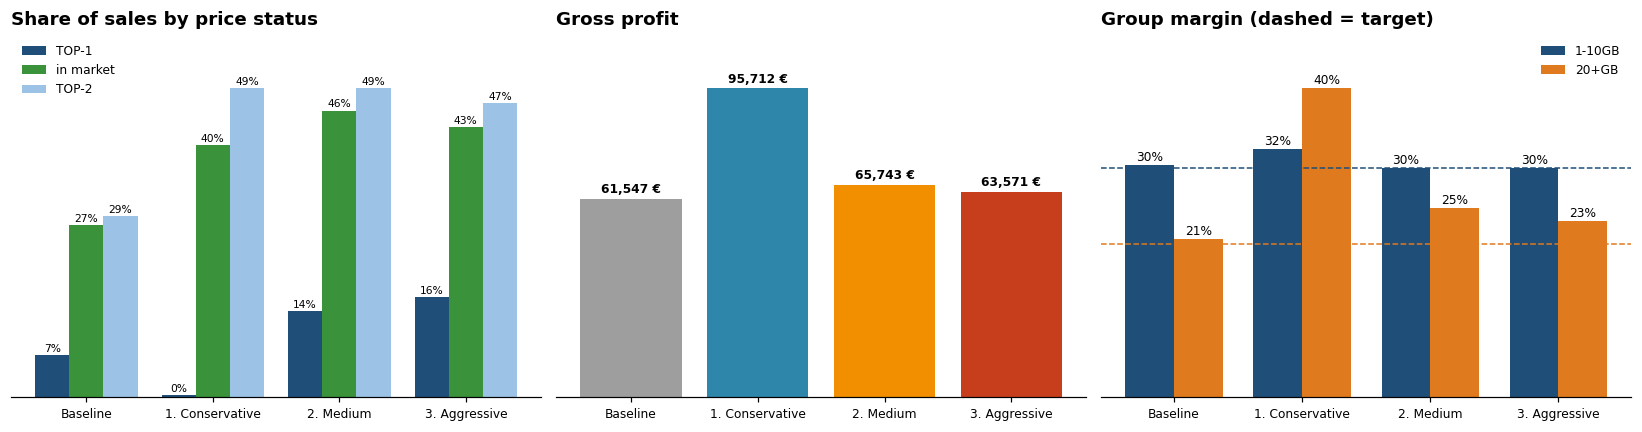

In [34]:
s = summary.T
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
w = 0.27; x_ = np.arange(len(s))
for j, (col, lab, c) in enumerate([("TOP-1, % of sales", "TOP-1", "#1F4E78"), ("in market, % of sales", "in market", "#3A923A"), ("TOP-2, % of sales", "TOP-2", "#9CC3E6")]):
    bars = ax[0].bar(x_ + (j - 1) * w, s[col], w, color=c, label=lab)
    ax[0].bar_label(bars, labels=[f"{v:.0%}" for v in s[col]], fontsize=7, padding=1)
ax[0].set_xticks(x_, s.index); ax[0].legend(fontsize=8, frameon=False); ax[0].set_title("Share of sales by price status")
bars = ax[1].bar(s.index, s["gross profit, €"], color=[COLORS[k] for k in prices])
ax[1].bar_label(bars, labels=[f"{v:,.0f} €" for v in s["gross profit, €"]], fontsize=8, fontweight="bold", padding=2)
ax[1].set_title("Gross profit")
for j, (col, c) in enumerate([("margin 1-10GB", "#1F4E78"), ("margin 20+GB", "#E07A1F")]):
    bars = ax[2].bar(x_ + (j - 0.5) * 0.38, s[col], 0.38, color=c, label=col.replace("margin ", ""))
    ax[2].bar_label(bars, labels=[f"{v:.0%}" for v in s[col]], fontsize=8, padding=1)
ax[2].axhline(TARGET_MARGIN["1-10GB"], color="#1F4E78", ls="--", lw=1); ax[2].axhline(TARGET_MARGIN["20+GB"], color="#E07A1F", ls="--", lw=1)
ax[2].set_xticks(x_, s.index); ax[2].legend(fontsize=8, frameon=False); ax[2].set_title("Group margin (dashed = target)")
for a_ in ax:
    clean_axis(a_, "y"); a_.tick_params(axis="x", labelsize=8); a_.set_ylim(0, a_.get_ylim()[1] * 1.12)
show("scenario_kpis")

## 3.1 How many plans and sales are out of market

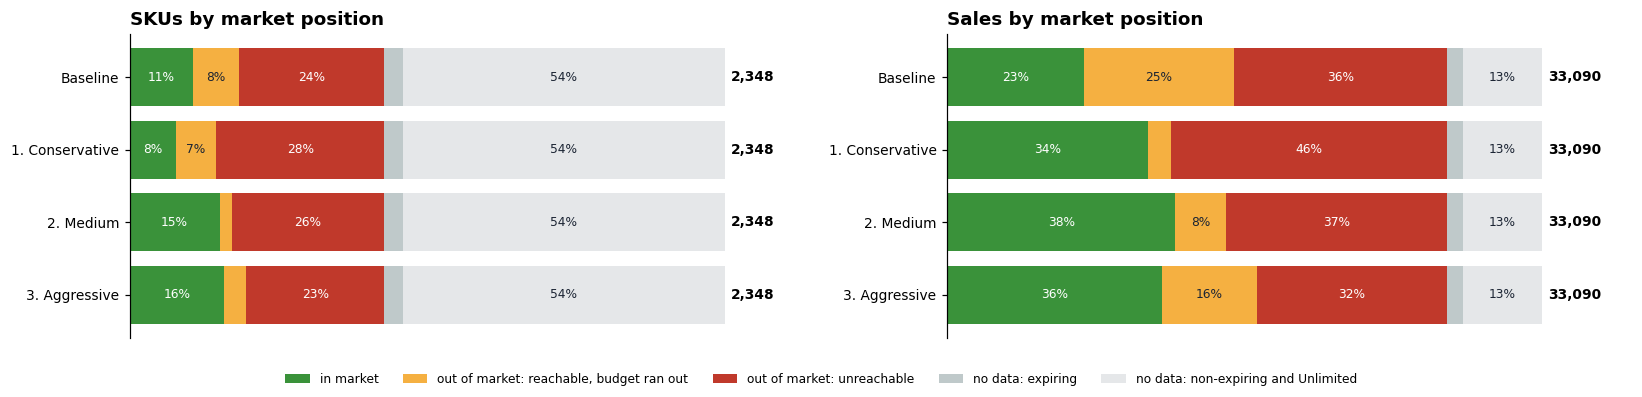

SKUs                            \
                                         Baseline 1. Conservative 2. Medium   
in market                                     250             182       355   
out of market: reachable, budget ran out      181             159        48   
out of market: unreachable                    574             664       602   
no data: expiring                              75              75        75   
no data: non-expiring and Unlimited          1268            1268      1268   

                                                          sales  \
                                         3. Aggressive Baseline   
in market                                          373     7614   
out of market: reachable, budget ran out            87     8334   
out of market: unreachable                         545    11838   
no data: expiring                                   75      918   
no data: non-expiring and Unlimited               1268     4386   

                                                                    \
                                         1. Conservative 2. Medium   
in market                                          11155     12691   
out of market: reachable, budget ran out            1280      2807   
out of market: unreachable                         15351     12288   
no data: expiring                                    918       918   
no data: non-expiring and Unlimited                 4386      4386   

                                                        
                                         3. Aggressive  
in market                                        11966  
out of market: reachable, budget ran out          5257  
out of market: unreachable                       10563  
no data: expiring                                  918  
no data: non-expiring and Unlimited               4386

In [35]:
REACH = ["in market", "out of market: reachable, budget ran out", "out of market: unreachable",
         "no data: expiring", "no data: non-expiring and Unlimited"]
REACH_COLORS = ["#3A923A", "#F5B041", "#C0392B", "#BFC9CA", "#E5E7E9"]

def reach_category(price, floor):
    st, h = status(price), df["has_comp"]
    reachable = to_x9(df["median_comp"] - 0.01, "down") >= floor
    cat = pd.Series("no data: non-expiring and Unlimited", index=df.index)
    cat[df["plan"] == "expiring"] = "no data: expiring"
    cat[h & ~st["in_market"] & reachable] = "out of market: reachable, budget ran out"
    cat[h & ~st["in_market"] & ~reachable] = "out of market: unreachable"
    cat[h & st["in_market"]] = "in market"
    return cat

cats = {k: reach_category(p, floors[k]) for k, p in prices.items()}
reach_sku = pd.DataFrame({names[k]: c.value_counts() for k, c in cats.items()}).reindex(REACH).fillna(0).astype(int)
reach_qty = pd.DataFrame({names[k]: df["qty"].groupby(c).sum() for k, c in cats.items()}).reindex(REACH).fillna(0).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.6))
for ax, data, title in [(axes[0], reach_sku, "SKUs"), (axes[1], reach_qty, "Sales")]:
    stacked_h(ax, data.T, REACH_COLORS)
    ax.set_title(f"{title} by market position")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, ncol=5, fontsize=8, loc="lower center", frameon=False)
show("reach_all_scenarios", rect=[0, 0.1, 1, 1])
pd.concat({"SKUs": reach_sku, "sales": reach_qty}, axis=1)

## 3.2 Market position and price changes — sales-weighted

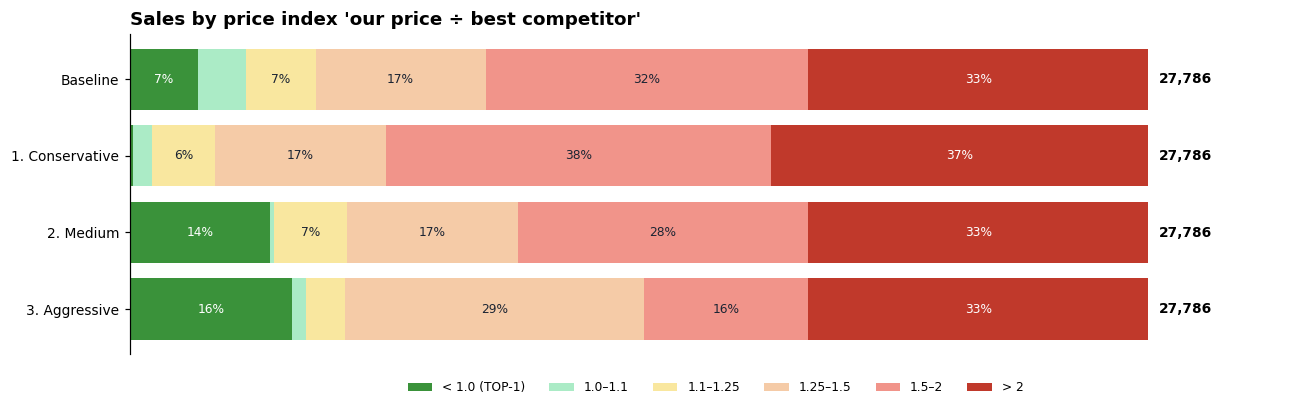

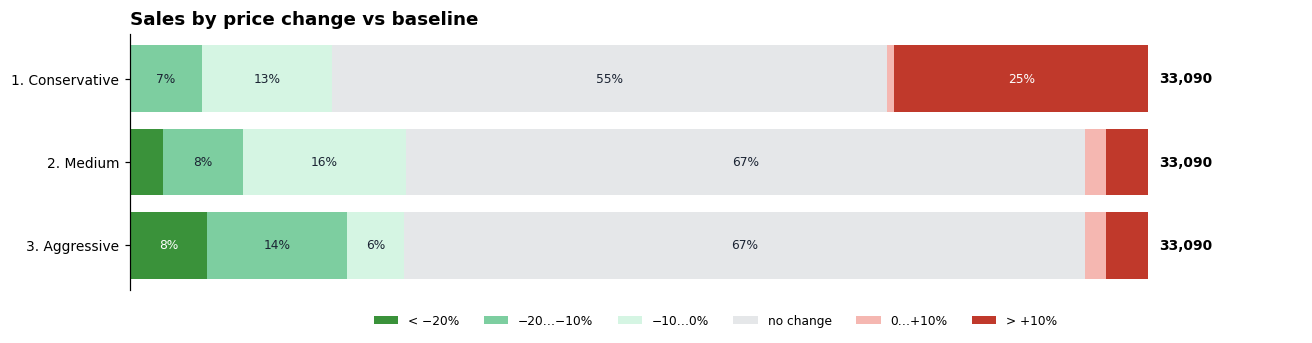

In [36]:
h = df["has_comp"]
bins, labels = [0, 1.0, 1.1, 1.25, 1.5, 2, np.inf], ["< 1.0 (TOP-1)", "1.0–1.1", "1.1–1.25", "1.25–1.5", "1.5–2", "> 2"]
corr = pd.DataFrame({names[k]: df.loc[h, "qty"].groupby(pd.cut(p[h] / df.loc[h, "best"], bins, labels=labels, right=False), observed=False).sum()
                     for k, p in prices.items()}).T
corr = corr.div(corr.sum(axis=1), axis=0)
cb, cl = [-np.inf, -0.20, -0.10, -0.005, 0.005, 0.10, np.inf], ["< −20%", "−20…−10%", "−10…0%", "no change", "0…+10%", "> +10%"]
chg = pd.DataFrame({names[k]: df["qty"].groupby(pd.cut(prices[k] / base - 1, cb, labels=cl), observed=False).sum() for k in CASES}).T
chg = chg.div(chg.sum(axis=1), axis=0)

corr_q = corr.mul(df.loc[h, "qty"].sum())              # back to sales for the totals
chg_q = chg.mul(TOTAL_QTY)
for data, colors, title, name in [
        (corr_q, ["#3A923A", "#ABEBC6", "#F9E79F", "#F5CBA7", "#F1948A", "#C0392B"], "Sales by price index 'our price ÷ best competitor'", "price_index_corridors"),
        (chg_q, ["#3A923A", "#7DCEA0", "#D5F5E3", "#E5E7E9", "#F5B7B1", "#C0392B"], "Sales by price change vs baseline", "price_change_corridors")]:
    fig, ax = plt.subplots(figsize=(12, 0.6 * len(data) + 1.4))
    stacked_h(ax, data, colors)
    ax.legend(ncol=6, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.05)); ax.set_title(title)
    show(name)

## 3.3 By market

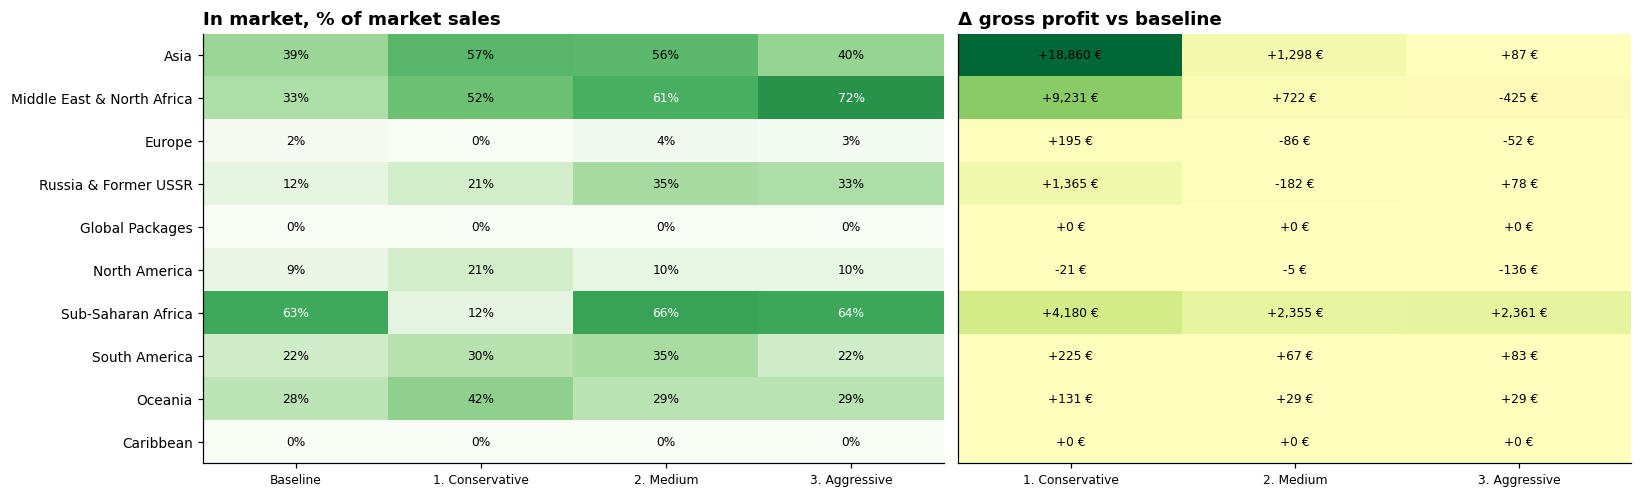

In [37]:
def by_market_profit(p):
    return (df["qty"] * (p - df["cost"])).groupby(df["market"]).sum()

def in_market_share(p, by="market"):
    t = df.loc[df["has_comp"], ["qty", by]].copy()
    t["qty_in"] = t["qty"] * status(p).loc[t.index, "in_market"]
    g = t.groupby(by)[["qty_in", "qty"]].sum()
    return g["qty_in"] / g["qty"].replace(0, np.nan)

order = df.groupby("market")["qty"].sum().sort_values().index
dp = pd.DataFrame({names[k]: by_market_profit(prices[k]) - by_market_profit(base) for k in CASES}).loc[order]
im = pd.DataFrame({names[k]: in_market_share(p) for k, p in prices.items()}).reindex(order)
order_desc = order[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
v1 = im.loc[order_desc].to_numpy(dtype=float)
ax[0].imshow(v1, cmap="Greens", vmin=0, vmax=1, aspect="auto")
for (r, c), v in np.ndenumerate(v1):
    ax[0].text(c, r, "—" if np.isnan(v) else f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if (not np.isnan(v) and v > 0.6) else "black")
ax[0].set_xticks(range(v1.shape[1]), im.columns, fontsize=8); ax[0].set_yticks(range(len(order_desc)), order_desc); ax[0].grid(False)
ax[0].set_title("In market, % of market sales")
v2 = dp.loc[order_desc].to_numpy(dtype=float); lim = np.nanmax(np.abs(v2))
ax[1].imshow(v2, cmap="RdYlGn", vmin=-lim, vmax=lim, aspect="auto")
for (r, c), v in np.ndenumerate(v2):
    ax[1].text(c, r, f"{v:+,.0f} €", ha="center", va="center", fontsize=8)
ax[1].set_xticks(range(v2.shape[1]), dp.columns, fontsize=8); ax[1].set_yticks([]); ax[1].grid(False)
ax[1].set_title("Δ gross profit vs baseline")
show("markets_by_scenario")

## 3.4 Choosing the scenario

In [38]:
s = summary.T.loc[[names[k] for k in CASES]]
s["eligible"] = (s["Δ profit vs baseline, €"] >= 0) & (s["Δ average price"] <= MAX_AVG_PRICE_INCREASE) & \
               (s["sales below cost"] <= MAX_SALES_BELOW_COST)
fit = s[s["eligible"]]
best_name = (fit if len(fit) else s)["in market, % of sales"].idxmax()
REC = [k for k in CASES if names[k] == best_name][0]
EXPORT = EXPORT_CASE or REC

reasons = []
for k in CASES:
    r = s.loc[names[k]]
    why = []
    if r["Δ profit vs baseline, €"] < 0: why.append("profit below baseline")
    if r["Δ average price"] > MAX_AVG_PRICE_INCREASE: why.append(f"average price +{pct(r['Δ average price'])} (> {pct(MAX_AVG_PRICE_INCREASE)})")
    if r["sales below cost"] > MAX_SALES_BELOW_COST: why.append(f"{r['sales below cost'] * TOTAL_QTY:,.0f} sales below cost (loss {r['loss on below-cost SKUs, €']:,.0f} €)")
    reasons.append(f"- **{names[k]}**: " + ("not eligible — " + "; ".join(why) if why else "eligible") +
                   f". In market {pct(r['in market, % of sales'])}, TOP-1 {pct(r['TOP-1, % of sales'])}, Δ profit {r['Δ profit vs baseline, €']:+,.0f} €.")
say(f'''
**Selection rule:** profit not below baseline, average price up by at most `MAX_AVG_PRICE_INCREASE` = {pct(MAX_AVG_PRICE_INCREASE)},
sales below cost at most `MAX_SALES_BELOW_COST` = {pct(MAX_SALES_BELOW_COST)}. Among the eligible scenarios we pick the one with the most sales in market.

{chr(10).join(reasons)}

→ **Recommended scenario: {names[REC]}.**
''')


**Selection rule:** profit not below baseline, average price up by at most `MAX_AVG_PRICE_INCREASE` = 5%,
sales below cost at most `MAX_SALES_BELOW_COST` = 0%. Among the eligible scenarios we pick the one with the most sales in market.

- **1. Conservative**: not eligible — average price +15% (> 5%). In market 40%, TOP-1 0%, Δ profit +34,166 €.
- **2. Medium**: eligible. In market 46%, TOP-1 14%, Δ profit +4,197 €.
- **3. Aggressive**: not eligible — 1,304 sales below cost (loss -38 €). In market 43%, TOP-1 16%, Δ profit +2,024 €.

→ **Recommended scenario: 2. Medium.**


## 3.5 Scenario details

The scenario shown here is set by `VIEW_CASE`.

In [39]:
K = VIEW_CASE
p = prices[K]
t = df.assign(price=p, revenue=df["qty"] * p, profit=df["qty"] * (p - df["cost"]), profit_base=df["qty"] * (base - df["cost"]))

def totals(by):
    g = t.groupby(by)
    out = pd.DataFrame({"sales": g["qty"].sum(), "revenue": g["revenue"].sum(), "profit": g["profit"].sum()})
    out["margin"] = out["profit"] / out["revenue"].replace(0, np.nan)
    out["Δ profit"] = out["profit"] - g["profit_base"].sum()
    out["in market, % of sales"] = in_market_share(p, by)
    return out.sort_values("sales", ascending=False)

say(f"**{names[K]}** — by market:")
totals("market")

**2. Medium** — by market:

,sales,revenue,profit,margin,Δ profit,"in market, % of sales"
market,,,,,,
Asia,11647,"90,522.93","24,274.63",0.27,"1,297.60",0.56
Middle East & North Africa,9718,"61,052.22","16,368.12",0.27,721.70,0.61
Europe,5013,"33,219.37","9,251.34",0.28,-86.40,0.04
Russia & Former USSR,4291,"19,869.29","5,687.65",0.29,-182.00,0.35
Global Packages,859,"13,377.71","3,501.13",0.26,0.00,0.00
North America,667,"3,488.13","1,012.91",0.29,-5.30,0.10
Sub-Saharan Africa,453,"9,275.77","4,277.12",0.46,"2,355.10",0.66
South America,324,"3,404.36","1,031.13",0.30,67.00,0.35
Oceania,102,"1,048.08",295.49,0.28,28.80,0.29


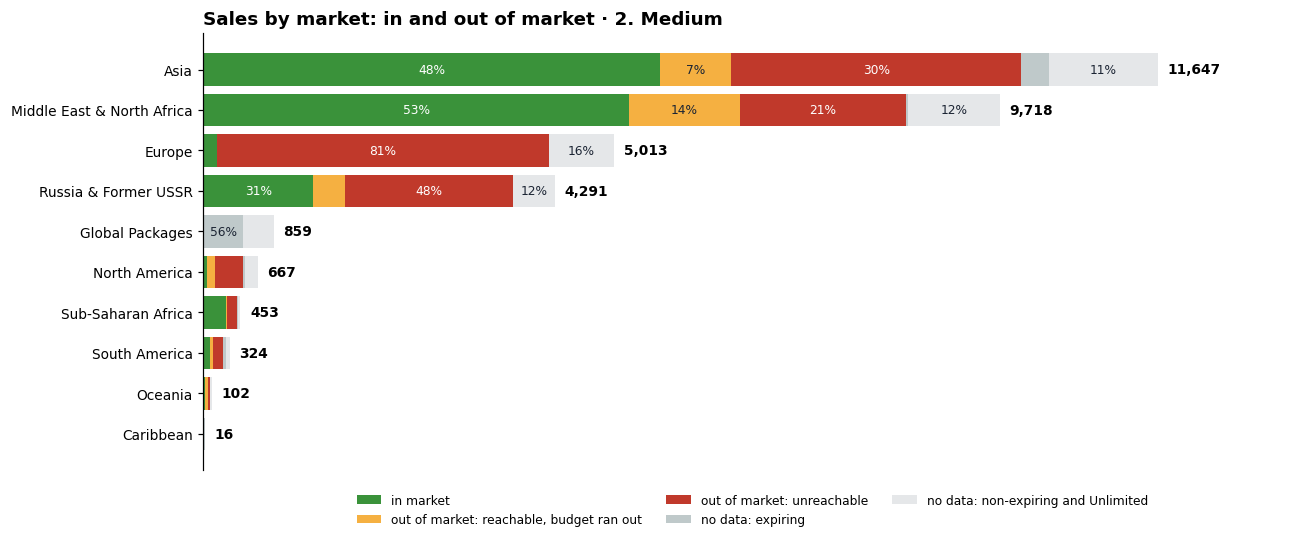


**2. Medium: 12,691 of 27,786 sales with competitor prices (46%) are in market.**
- **In market:** led by Asia (5,567), Middle East & North Africa (5,192), Russia & Former USSR (1,339).
- **Unreachable even at our minimum price:** 12,288 sales (44%) — a procurement issue, mostly Europe (4,046), Asia (3,544), Russia & Former USSR (2,054).
  In Europe this is 96% of sales with competitor data.
- **Within reach with more margin budget:** 2,807 sales (10%), mainly Middle East & North Africa (1,357), Asia (869).
- **No competitor data:** 5,304 sales (non-expiring and Unlimited packs, priced by the grid rules).


,in market,"out of market: reachable, budget ran out",out of market: unreachable,no data: expiring,no data: non-expiring and Unlimited,total
market,,,,,,
Asia,5567,869,3544,337,1330,11647
Middle East & North Africa,5192,1357,2022,20,1127,9718
Europe,165,4,4046,0,798,5013
Russia & Former USSR,1339,389,2054,0,509,4291
Global Packages,0,9,0,481,369,859
North America,48,93,346,20,160,667
Sub-Saharan Africa,273,16,126,14,24,453
South America,84,40,117,32,51,324
Oceania,23,30,25,7,17,102


In [40]:
cat = cats[K]
mk_reach = df["qty"].groupby([df["market"], cat]).sum().unstack(fill_value=0).reindex(columns=REACH, fill_value=0)
mk_reach = mk_reach.loc[mk_reach.sum(axis=1).sort_values().index]
mk_total = mk_reach.sum(axis=1)

fig, ax = plt.subplots(figsize=(12, 5))
stacked_h(ax, mk_reach.iloc[::-1], REACH_COLORS)
ax.set_title(f"Sales by market: in and out of market · {names[K]}")
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.03))
show("market_reach_selected")

# slide-ready summary
nodata = mk_reach[["no data: expiring", "no data: non-expiring and Unlimited"]].sum(axis=1)
inm, unr = mk_reach["in market"], mk_reach["out of market: unreachable"]
bud = mk_reach["out of market: reachable, budget ran out"]
with_comp = mk_total - nodata
big = with_comp[with_comp >= 500].index                       # markets with enough sales for a share to mean something
unr_share = (unr[big] / with_comp[big]).sort_values(ascending=False)
top = lambda s, n: ", ".join(f"{i} ({v:,.0f})" for i, v in s.sort_values(ascending=False).head(n).items() if v > 0)
say(f'''
**{names[K]}: {inm.sum():,.0f} of {with_comp.sum():,.0f} sales with competitor prices ({pct(inm.sum() / with_comp.sum())}) are in market.**
- **In market:** led by {top(inm, 3)}.
- **Unreachable even at our minimum price:** {unr.sum():,.0f} sales ({pct(unr.sum() / with_comp.sum())}) — a procurement issue, mostly {top(unr, 3)}.
  In {unr_share.index[0]} this is {pct(unr_share.iloc[0])} of sales with competitor data.
- **Within reach with more margin budget:** {bud.sum():,.0f} sales ({pct(bud.sum() / with_comp.sum())}), mainly {top(bud, 2)}.
- **No competitor data:** {nodata.sum():,.0f} sales (non-expiring and Unlimited packs, priced by the grid rules).
''')
mk_reach.iloc[::-1].assign(total=mk_total.iloc[::-1])

In [41]:
top10 = totals("region").head(10)
say(f"Top 10 destinations by sales — {names[K]}:")
top10

Top 10 destinations by sales — 2. Medium:

,sales,revenue,profit,margin,Δ profit,"in market, % of sales"
region,,,,,,
Turkey,6583,"31,668.77","5,882.33",0.19,"-2,401.90",0.65
China,3853,"26,619.77","5,961.82",0.22,-913.60,0.58
Thailand,2194,"17,063.16","4,067.56",0.24,-55.40,0.65
Europe,2043,"16,067.37","4,406.52",0.27,0.00,0.00
Vietnam,1905,"12,047.55","2,825.81",0.23,-220.60,0.65
Egypt,1891,"15,938.79","6,370.19",0.40,"2,803.90",0.65
Georgia,1295,"6,822.75","1,963.44",0.29,-76.80,0.14
Asia 26,892,"10,428.58","2,957.73",0.28,0.00,0.00
Kazakhstan,788,"3,367.32",998.13,0.30,32.40,0.38


### Where we stand: price position vs margin

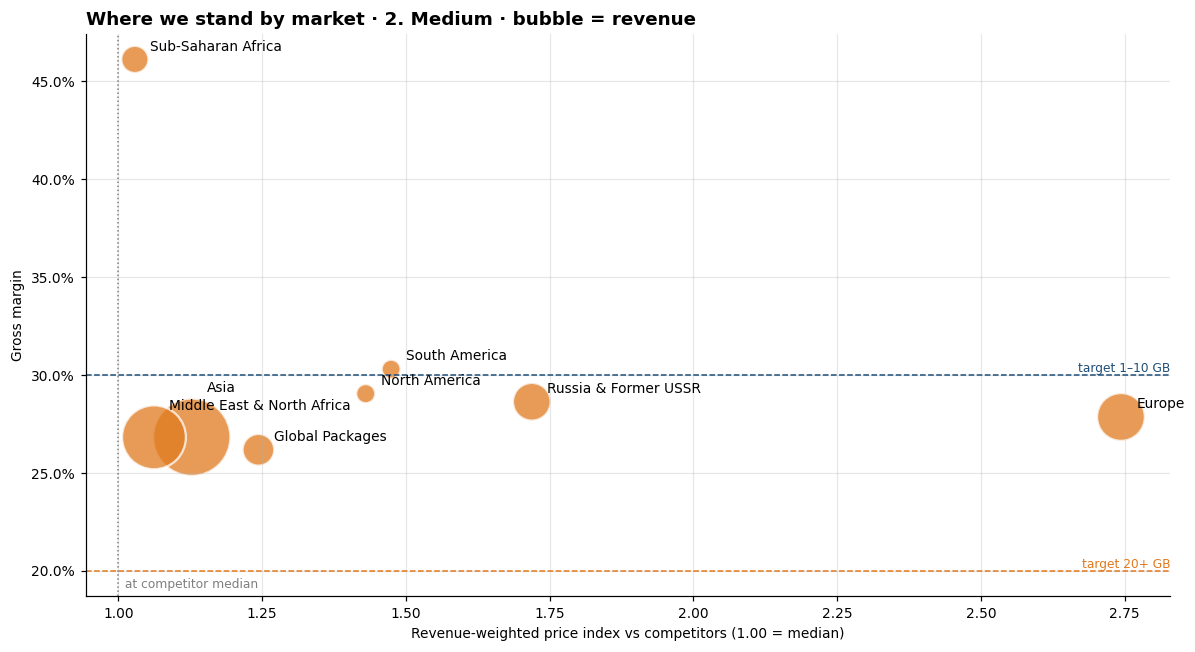

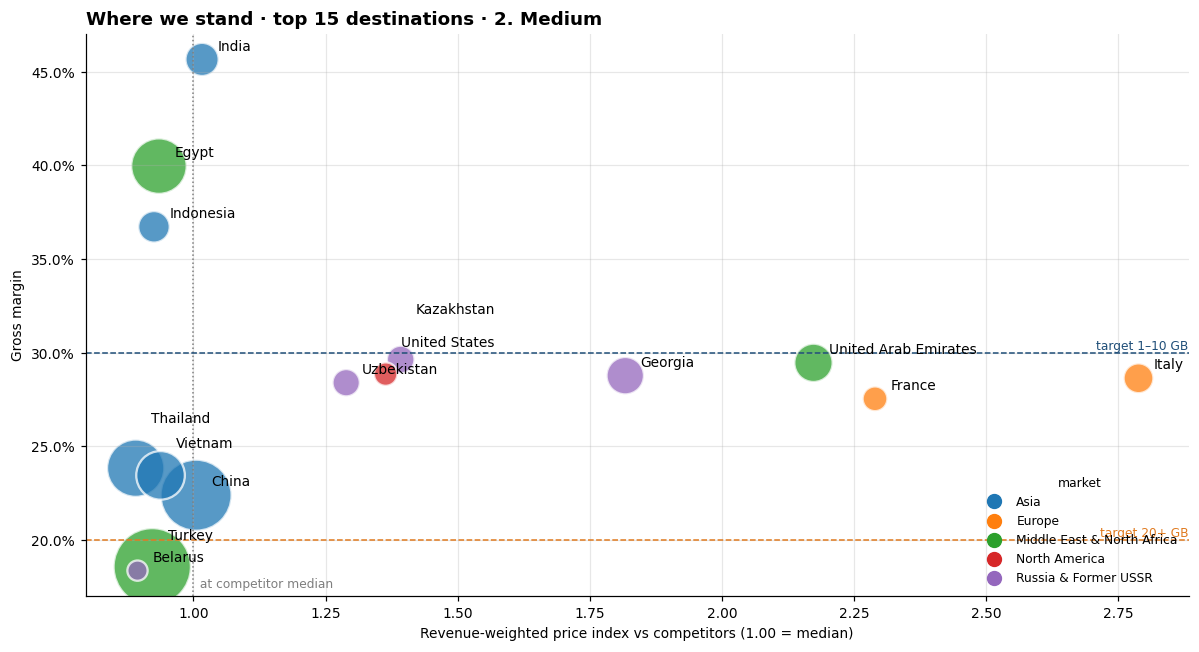

**Sub-Saharan Africa** is priced furthest below the competitor median (index 1.03, margin 46%); **Europe** is furthest above it (index 2.74, margin 28%).

,price index vs median,gross margin,revenue,market
market,,,,
Asia,1.13,27%,"90,523 €",Asia
Middle East & North Africa,1.06,27%,"61,052 €",Middle East & North Africa
Europe,2.74,28%,"33,219 €",Europe
Russia & Former USSR,1.72,29%,"19,869 €",Russia & Former USSR
Global Packages,1.24,26%,"13,378 €",Global Packages
Sub-Saharan Africa,1.03,46%,"9,276 €",Sub-Saharan Africa
North America,1.43,29%,"3,488 €",North America
South America,1.47,30%,"3,404 €",South America


In [42]:
def where_we_stand(by, keep=None):
    w = t[t["has_comp"]].assign(rev=lambda d: d["qty"] * d["price"], idx=lambda d: d["price"] / d["median_comp"])
    pos = (w["rev"] * w["idx"]).groupby(w[by]).sum() / w.groupby(by)["rev"].sum()      # revenue-weighted index vs median
    g = t.groupby(by)
    out = pd.DataFrame({"price index vs median": pos, "gross margin": g["profit"].sum() / g["revenue"].sum().replace(0, np.nan),
                        "revenue": g["revenue"].sum(), "market": g["market"].first()}).dropna()
    return out.loc[keep] if keep is not None else out

def stand_plot(d, title, name, color_by=None):
    fig, ax = plt.subplots(figsize=(11, 6))
    palette = dict(zip(sorted(d[color_by].unique()), plt.cm.tab10.colors)) if color_by else None
    colors = [palette[m] for m in d[color_by]] if color_by else ["#3A923A" if v <= 1 else "#E07A1F" for v in d["price index vs median"]]
    ax.scatter(d["price index vs median"], d["gross margin"], s=d["revenue"] / d["revenue"].max() * 2500 + 60,
               c=colors, alpha=0.75, edgecolor="white", lw=1.5)
    # simple label placement: push labels apart vertically when points are close
    pts = d.sort_values("gross margin")
    xr = d["price index vs median"].max() - d["price index vs median"].min() or 1
    yr = d["gross margin"].max() - d["gross margin"].min() or 1
    placed = []
    for nm, r in pts.iterrows():
        x0, y0, dy = r["price index vs median"], r["gross margin"], 6
        for (px, py, pdy) in placed:
            if abs(px - x0) / xr < 0.12 and abs(py - y0) / yr < 0.06:
                dy = pdy + 12
        placed.append((x0, y0, dy))
        ax.annotate(nm, (x0, y0), xytext=(10, dy), textcoords="offset points", fontsize=9)
    ax.axvline(1, color="#7F7F7F", ls=":", lw=1)
    ax.text(1.005, 0.01, " at competitor median", fontsize=8, color="#7F7F7F", va="bottom", transform=ax.get_xaxis_transform())
    for tm, lab, c in [(TARGET_MARGIN["1-10GB"], "target 1–10 GB", "#1F4E78"), (TARGET_MARGIN["20+GB"], "target 20+ GB", "#E07A1F")]:
        ax.axhline(tm, color=c, ls="--", lw=1); ax.text(ax.get_xlim()[1], tm, lab, ha="right", va="bottom", fontsize=8, color=c)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set(xlabel="Revenue-weighted price index vs competitors (1.00 = median)", ylabel="Gross margin")
    if color_by:
        ax.legend([plt.Line2D([0], [0], marker="o", ls="", color=c, ms=9) for c in palette.values()], palette.keys(),
                  fontsize=8, frameon=False, loc="lower right", title="market", title_fontsize=8)
    ax.set_title(title)
    show(name)

ws_mk = where_we_stand("market")
ws_mk = ws_mk[ws_mk["revenue"] >= 0.005 * ws_mk["revenue"].sum()]      # drop markets with negligible revenue
stand_plot(ws_mk, f"Where we stand by market · {names[K]} · bubble = revenue", "where_we_stand_markets")
top_dest = t[~t["subregion"].isin(["Regional Packages", "Global Packages"])].groupby("region")["qty"].sum().nlargest(15).index
ws_dest = where_we_stand("region", [r for r in top_dest if r in where_we_stand("region").index])
stand_plot(ws_dest, f"Where we stand · top 15 destinations · {names[K]}", "where_we_stand_destinations", color_by="market")
cheap, dear = ws_mk["price index vs median"].idxmin(), ws_mk["price index vs median"].idxmax()
say(f"**{cheap}** is priced furthest below the competitor median (index {ws_mk.loc[cheap, 'price index vs median']:.2f}, margin {pct(ws_mk.loc[cheap, 'gross margin'])}); "
    f"**{dear}** is furthest above it (index {ws_mk.loc[dear, 'price index vs median']:.2f}, margin {pct(ws_mk.loc[dear, 'gross margin'])}).")
ws_mk.sort_values("revenue", ascending=False).style.format({"price index vs median": "{:.2f}", "gross margin": "{:.0%}", "revenue": "{:,.0f} €"})

### Revenue in and out of market by pack size

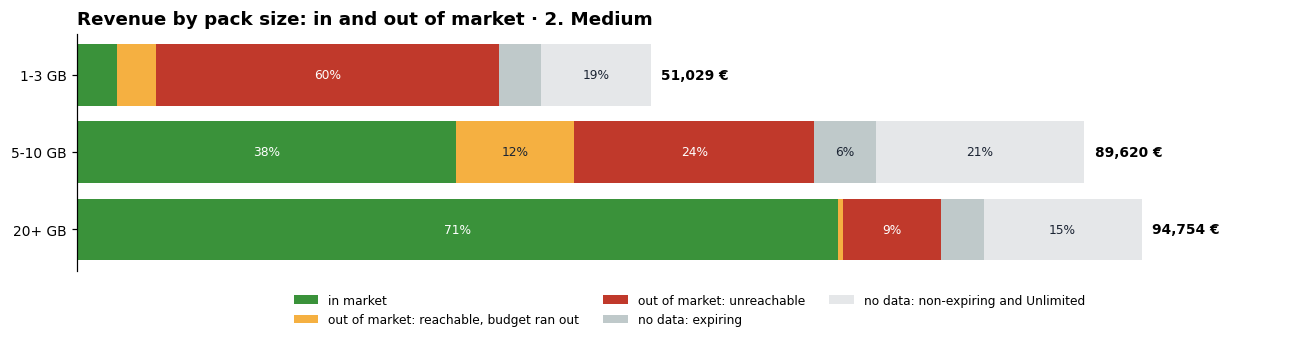

In market by revenue: 1-3 GB — 7%, 5-10 GB — 38%, 20+ GB — 71%. Out of reach even at the minimum price: 60,548 € of revenue.

,in market,"out of market: reachable, budget ran out",out of market: unreachable,no data: expiring,no data: non-expiring and Unlimited,total
1-3 GB,"3,558.00","3,423.00","30,557.00","3,741.00","9,751.00","51,029.00"
5-10 GB,"33,712.00","10,547.00","21,339.00","5,520.00","18,501.00","89,620.00"
20+ GB,"67,716.00",484.00,"8,652.00","3,830.00","14,072.00","94,754.00"


In [43]:
rev_b = (t["qty"] * t["price"]).groupby([t["bucket"], cats[K]]).sum().unstack(fill_value=0).reindex(columns=REACH, fill_value=0)
rev_b = rev_b.reindex([b for b in BUCKETS if b in rev_b.index])
rev_b.index = [f"{b.replace('GB', ' GB')}" for b in rev_b.index]
fig, ax = plt.subplots(figsize=(12, 3.2))
stacked_h(ax, rev_b, REACH_COLORS, total_fmt="{:,.0f} €")
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.05))
ax.set_title(f"Revenue by pack size: in and out of market · {names[K]}")
show("revenue_by_bucket_selected")
inr = rev_b["in market"] / rev_b.sum(axis=1)
say(f"In market by revenue: " + ", ".join(f"{i} — {pct(v)}" for i, v in inr.items()) + ". "
    f"Out of reach even at the minimum price: {rev_b['out of market: unreachable'].sum():,.0f} € of revenue.")
rev_b.assign(total=rev_b.sum(axis=1)).round(0)

### Top 20 SKUs with the new prices

In [44]:
st_k = status(p)
top20n = t.nlargest(20, "qty")[["sku", "segment", "qty", "cost"]].copy()
top20n["baseline price"] = base[top20n.index]
top20n["new price"] = p[top20n.index]
top20n["Δ price"] = top20n["new price"] / top20n["baseline price"] - 1
top20n["margin"] = (top20n["new price"] - top20n["cost"]) / top20n["new price"]
top20n["best"] = df.loc[top20n.index, "best"]; top20n["median"] = df.loc[top20n.index, "median_comp"]
top20n["status"] = np.select([st_k.loc[top20n.index, "top1"], st_k.loc[top20n.index, "in_market"], df.loc[top20n.index, "has_comp"]],
                             ["TOP-1", "in market", "out of market"], "no data")
say(f"Top 20 SKUs in **{names[K]}**: {int(top20n['status'].isin(['TOP-1', 'in market']).sum())} of 20 in market "
    f"({pct(top20n.loc[top20n['status'].isin(['TOP-1', 'in market']), 'qty'].sum() / top20n['qty'].sum())} of their sales).")
top20n.style.format({"qty": "{:,.0f}", "cost": "{:.2f}", "baseline price": "{:.2f}", "new price": "{:.2f}", "Δ price": "{:+.0%}",
                     "margin": "{:.0%}", "best": "{:.2f}", "median": "{:.2f}"}, na_rep="—").hide(axis="index")

Top 20 SKUs in **2. Medium**: 10 of 20 in market (60% of their sales).

sku,segment,qty,cost,baseline price,new price,Δ price,margin,best,median,status
TR-5-GB-30,expiring | 5-10GB,"1,363",2.17,3.09,2.69,-13%,19%,1.76,2.70,in market
TR-20-GB-30,expiring | 20+GB,"1,211",7.34,9.19,9.19,+0%,20%,7.04,10.81,in market
TR-1-GB-30,expiring | 1-3GB,"1,080",0.51,0.69,0.69,+0%,26%,0.35,0.54,out of market
TR-10-GB-30,expiring | 5-10GB,970,3.99,5.69,5.39,-5%,26%,3.52,4.46,out of market
TR-3-GB-30,expiring | 1-3GB,915,1.42,1.99,1.59,-20%,11%,1.06,1.62,in market
CN-10-GB-30,expiring | 5-10GB,883,4.51,6.39,5.99,-6%,25%,4.13,6.07,in market
CN-20-GB-30,expiring | 20+GB,853,7.51,9.39,9.39,+0%,20%,7.78,12.14,in market
VN-20-GB-30,expiring | 20+GB,791,6.76,8.49,8.39,-1%,19%,8.45,12.32,TOP-1
TH-20-GB-30,expiring | 20+GB,770,6.76,8.49,8.49,+0%,20%,5.76,12.32,in market
CN-3-GB-30,expiring | 1-3GB,595,2.25,3.19,3.19,+0%,29%,1.61,1.82,out of market


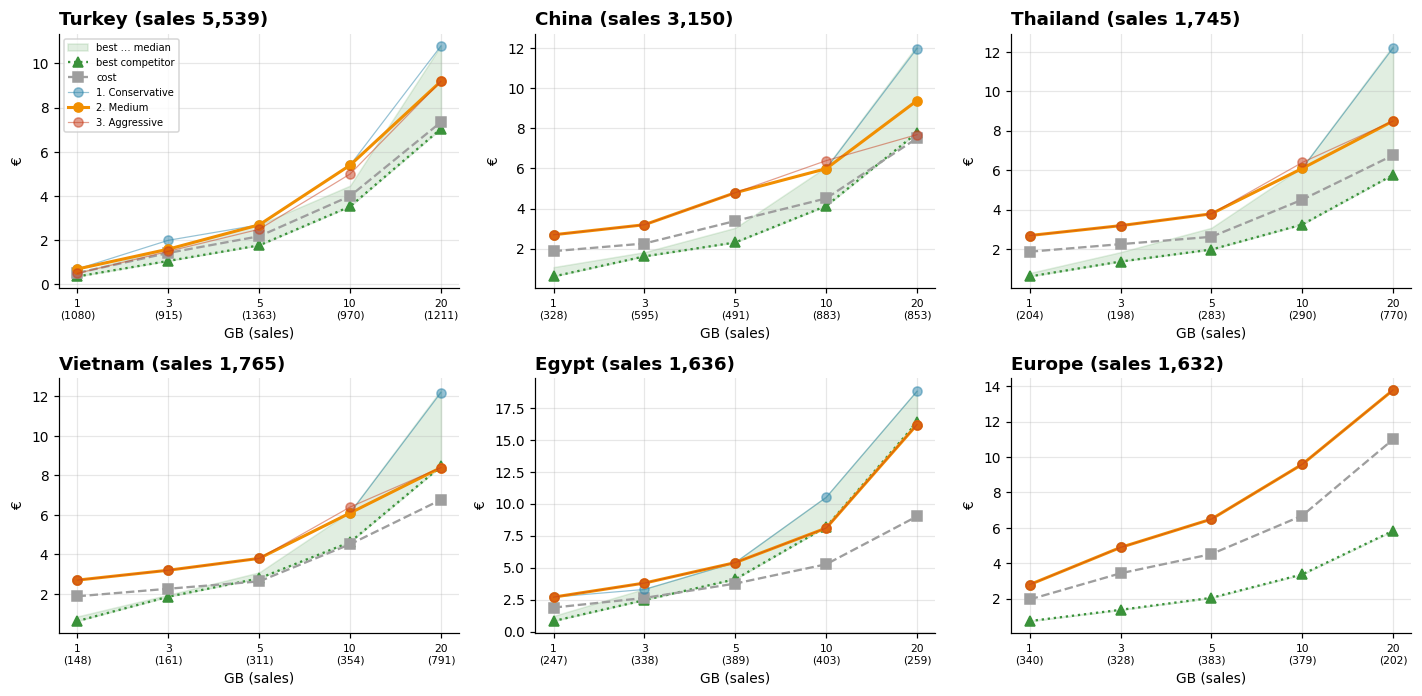

In [45]:
LADDER_LOG = False
LADDER_MAX_GB = 20
top6 = t[t["plan"] == "expiring"].groupby("region")["qty"].sum().nlargest(6).index
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, rg in zip(axes.ravel(), top6):
    s_ = t[(t["region"] == rg) & (t["validity"] == 30) & (t["vol"] <= LADDER_MAX_GB)].sort_values("vol")
    xs = [f"{v:.0f}\n({q:.0f})" for v, q in zip(s_["vol"], s_["qty"])]
    ax.fill_between(xs, s_["best"], s_["median_comp"], color="#3A923A", alpha=0.15, label="best … median")
    ax.plot(xs, s_["best"], "^:", color="#3A923A", label="best competitor")
    ax.plot(xs, s_["cost"], "s--", color="#9E9E9E", label="cost")
    for k in CASES:
        ax.plot(xs, prices[k][s_.index], "o-", color=COLORS[k], lw=2 if k == K else 0.8, alpha=1 if k == K else 0.5, label=names[k])
    ax.set(title=f"{rg} (sales {s_['qty'].sum():,.0f})", xlabel="GB (sales)", ylabel="€", yscale="log" if LADDER_LOG else "linear")
    ax.tick_params(axis="x", labelsize=7)
axes.ravel()[0].legend(fontsize=6.5); show("ladders_top6")

## 3.6 Conclusions

In [46]:
r = summary[names[REC]]; b0 = summary[names[0]]
cat = cats[REC]
qc = lambda name: df.loc[cat == name, "qty"].sum()
unreach_mk = df.loc[cat == "out of market: unreachable"].groupby("market")["qty"].sum() / df.groupby("market")["qty"].sum()
top_unreach = df.loc[cat == "out of market: unreachable"].groupby("region")["qty"].sum().nlargest(5).index.tolist()
others = [k for k in CASES if k != REC]
say(f'''
1. **Recommended scenario — {names[REC]}** ({floor_desc(CASES[REC])},
   reference — the {'second' if CASES[REC]['target'] == 'second' else 'best'} competitor):
   - in market **{pct(r['in market, % of sales'])}** of sales vs {pct(b0['in market, % of sales'])} in the baseline;
   - TOP-1 — {pct(r['TOP-1, % of sales'])} vs {pct(b0['TOP-1, % of sales'])};
   - gross profit {r['gross profit, €']:,.0f} € ({r['Δ profit vs baseline, €']:+,.0f} € vs baseline), average price {r['Δ average price']:+.1%};
   - price above baseline for {pct(r['sales: price up'])} of sales and below for {pct(r['sales: price down'])}.
2. **All rules hold** in all scenarios: group margin ≥ {pct(TARGET_MARGIN['1-10GB'])} / {pct(TARGET_MARGIN['20+GB'])}, SKU price floor,
   volume ladder, expiring cheaper than non-expiring, premium at most +{NOEXP_MAX_EUR:.0f} € unless parity, X.Y9 format.
3. **Out of market** in the recommended scenario (of sales with competitor prices):
   - unreachable even at the minimum price — {pct(qc('out of market: unreachable') / QTY_COMP)} ({qc('out of market: unreachable'):,.0f} sales,
     {int((cat == 'out of market: unreachable').sum())} SKUs). This is a **procurement** issue. Worst market: {unreach_mk.idxmax()}
     ({pct(unreach_mk.max())} of its sales); main destinations: {", ".join(top_unreach)};
   - reachable, but the margin budget ran out — {pct(qc('out of market: reachable, budget ran out') / QTY_COMP)} ({qc('out of market: reachable, budget ran out'):,.0f} sales).
4. **Other scenarios:**
''' + "\n".join(f"   - {names[k]}: in market {pct(summary.loc['in market, % of sales', names[k]])}, Δ profit "
                f"{summary.loc['Δ profit vs baseline, €', names[k]]:+,.0f} €, average price {summary.loc['Δ average price', names[k]]:+.1%}, "
                f"below cost {summary.loc['sales below cost', names[k]] * TOTAL_QTY:,.0f} sales (loss {summary.loc['loss on below-cost SKUs, €', names[k]]:,.0f} €)." for k in others) + f'''
5. **Limitations:** sales volumes are assumed constant; elasticity is unknown. There are no competitor prices for non-expiring packs.
   Next step — a price test on positions that moved into the market and on price increases.
''')


1. **Recommended scenario — 2. Medium** (min SKU margin 5%,
   reference — the best competitor):
   - in market **46%** of sales vs 27% in the baseline;
   - TOP-1 — 14% vs 7%;
   - gross profit 65,743 € (+4,197 € vs baseline), average price +1.8%;
   - price above baseline for 6% of sales and below for 27%.
2. **All rules hold** in all scenarios: group margin ≥ 30% / 20%, SKU price floor,
   volume ladder, expiring cheaper than non-expiring, premium at most +20 € unless parity, X.Y9 format.
3. **Out of market** in the recommended scenario (of sales with competitor prices):
   - unreachable even at the minimum price — 44% (12,288 sales,
     602 SKUs). This is a **procurement** issue. Worst market: Europe
     (81% of its sales); main destinations: Europe, China, Turkey, Georgia, Italy;
   - reachable, but the margin budget ran out — 10% (2,807 sales).
4. **Other scenarios:**
   - 1. Conservative: in market 40%, Δ profit +34,166 €, average price +14.8%, below cost 0 sales (loss 0 €).
   - 3. Aggressive: in market 43%, Δ profit +2,024 €, average price +0.9%, below cost 1,304 sales (loss -38 €).
5. **Limitations:** sales volumes are assumed constant; elasticity is unknown. There are no competitor prices for non-expiring packs.
   Next step — a price test on positions that moved into the market and on price increases.


## 3.7 Export

In [47]:
wb = load_workbook(INPUT_FILE)
ws = wb["ALL_PRICES_REDUCED"]
headers = [c.value for c in ws[1]]
price_col = headers.index("Recommended price,  euro") + 1
first_new = max(i for i, hd in enumerate(headers, 1) if hd) + 1
style = ws.cell(1, price_col)
new_cols = {**{f"recommended_price {k}": prices[k] for k in CASES}, "best_comp (clean)": df["best"], "median_comp (clean)": df["median_comp"]}
for j, (name, values) in enumerate(new_cols.items()):
    cell = ws.cell(1, first_new + j, name)
    cell.font, cell.fill, cell.alignment = copy(style.font), copy(style.fill), copy(style.alignment)
    for r_, v in enumerate(values, start=2):
        ws.cell(r_, first_new + j, None if pd.isna(v) else float(v)).number_format = "#,##0.00"
for r_, v in enumerate(prices[EXPORT], start=2):
    ws.cell(r_, price_col, float(v))
if "Cases_summary" in wb.sheetnames:
    del wb["Cases_summary"]
sh = wb.create_sheet("Cases_summary")
sh.append(["metric"] + list(summary.columns))
for metric, row in summary.iterrows():
    sh.append([metric] + [None if pd.isna(v) else float(v) for v in row])
wb.save(OUTPUT_FILE)
say(f"Saved to `{OUTPUT_FILE.name}`. 'Recommended price, euro' holds **{names[EXPORT]}**; all scenarios are in columns `recommended_price {"/".join(map(str, CASES))}`.")

Saved to `Pricing_analyst_task_PY_3cases.xlsx`. 'Recommended price, euro' holds **2. Medium**; all scenarios are in columns `recommended_price 1/2/3`.